# **Shopping Mission Segmentation in Online Grocery Orders**

## Project Overview

This project explores whether grocery orders can be grouped into distinct **shopping missions** based on how the products in each basket are distributed across supermarket departments.

The analysis uses transaction level grocery data and transforms individual product records into order level basket profiles. Dimensionality reduction and clustering techniques are then used to identify recurring purchase patterns.

**Main Research Question**

**Can grocery orders be grouped into meaningful and interpretable shopping missions based on their department composition?**

**Secondary Question**

For customers with multiple observed orders:

**Do customers tend to repeat the same shopping mission, or do they switch between different types of purchases over time?**

**Potential Applications**

The resulting shopping missions could support:

- product recommendations,
- cross selling strategies,
- targeted promotions,
- basket analysis,
- and understanding how purchasing behavior changes between visits.

### Data Source

The analysis uses the ECommerce consumer behaviour dataset available through Kaggle.

The dataset is accessed through:

hunter0007/ecommerce-dataset-for-predictive-marketing-2023

It is downloaded directly at runtime using kagglehub, so the raw data are not stored in this repository.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# analysis settings

random_state = 42
silhouette_sample = 10_000
small_basket_max = 3
basket_cap = 40

pc_candidates = [7, 10, 13]
k_range = range(2, 11)
candidate_ks = [6, 7, 8]

final_pcs = 7
final_k = 8

final_n_init = 50

candidate_ks = sorted(
    set(candidate_ks) | {final_k}
)

seed_values = [1, 2, 3, 4, 5]

consecutive_only = True

cluster_names = {}

In [2]:
# plot settings

dark = "#1F2A37"
accent = "#E4572E"
grey = "#7A8794"
grid = "#E5E5E5"
spine = "#BBBBBB"

cluster_colors = [dark, accent, "#2F7F93", "#E0A100", "#6B8E23",
                  "#8E5A9B", "#C45C8A", grey, "#A0522D", "#3E8E41"]

pc_colors = dict(zip(pc_candidates, [accent, dark, grey]))

representation_colors = {"Raw proportions": grey, "Hellinger": accent}

cmap_diverging = LinearSegmentedColormap.from_list("div", ["#2F5D8A", "#F7F7F7", accent])
cmap_sequential = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", accent])

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (10, 5.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": spine,
    "axes.labelcolor": dark,
    "axes.labelsize": 11,
    "axes.labelpad": 10,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 15,
    "axes.titlecolor": dark,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.prop_cycle": cycler(color=cluster_colors),
    "grid.color": grid,
    "grid.linewidth": 0.8,
    "xtick.color": dark,
    "ytick.color": dark,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "text.color": dark,
    "legend.frameon": False,
    "legend.fontsize": 11,
})

def cluster_color(c):
    return cluster_colors[int(c) % len(cluster_colors)]


def cluster_label(c, short=False):
    name = cluster_names.get(int(c))
    if short:
        return f"C{c}"
    return f"C{c}: {name}" if name else f"Cluster {c}"


def style_axes(ax, title=None, xlabel=None, ylabel=None, grid="y", title_size=None):
    if title is not None:
        ax.set_title(title, **({"fontsize": title_size} if title_size else {}))
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid)
    return ax


def thousands(ax, axis="y"):
    fmt = FuncFormatter(lambda v, _: f"{int(v):,}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def percent_axis(ax, axis="x"):
    fmt = FuncFormatter(lambda v, _: f"{v:.0f}%")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def add_median_mean(ax, median, mean):
    ax.axvline(median, color=accent, linestyle="--", linewidth=1.8, label=f"Median: {median:.0f}")
    ax.axvline(mean, color=grey, linestyle=":", linewidth=1.8, label=f"Mean: {mean:.1f}")
    ax.legend(loc="upper right")


def barh_chart(series, title, xlabel, fmt="{:.1f}%", figsize=(10, 7)):
    data = series.sort_values()
    colors = [dark] * len(data)
    colors[-1] = accent
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(data.index, data.values, height=0.7, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=4, fontsize=9, color=dark)
    style_axes(ax, title, xlabel, "", grid="x")
    percent_axis(ax, "x")
    ax.set_xlim(0, data.max() * 1.12)
    plt.tight_layout()
    plt.show()


def annotated_heatmap(ax, matrix, cmap, vmin, vmax, fmt="{:.0f}", min_abs=0, fontsize=8):
    values = np.asarray(matrix, dtype=float)
    im = ax.imshow(values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.grid(False)
    span = vmax - vmin
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if abs(v) >= min_abs:
                strong = abs(v - (vmin + span / 2)) > 0.35 * span
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                        color="white" if strong else dark)
    return im

In [3]:
!pip -q install kagglehub

In [4]:
import kagglehub

dataset = "hunter0007/ecommerce-dataset-for-predictive-marketing-2023"
file_name = "ECommerce_consumer behaviour.csv"

data_path = kagglehub.dataset_download(dataset)
df = pd.read_csv(os.path.join(data_path, file_name))

100%|██████████| 15.2M/15.2M [00:00<00:00, 99.3MB/s]

Extracting files...


## 1. Data Understanding

Before modeling, the structure of the dataset must be understood.

Each row in the raw dataset represents one product within one order.

Because an order can contain several products, the same order appears across multiple rows.

The dataset contains three important levels of analysis:

**User:** the customer making the purchases.

**Order:** one shopping event or basket.

**Product:** an individual product contained within an order.

In [5]:
display(df.head())

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name
0,2425083,49125,1,2,18,NaN,17,1,0,13,pantry,baking ingredients
1,2425083,49125,1,2,18,NaN,91,2,0,16,dairy eggs,soy lactosefree
2,2425083,49125,1,2,18,NaN,36,3,0,16,dairy eggs,butter
3,2425083,49125,1,2,18,NaN,83,4,0,4,produce,fresh vegetables
4,2425083,49125,1,2,18,NaN,83,5,0,4,produce,fresh vegetables


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2019501 entries, 0 to 2019500
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   order_number            int64  
 3   order_dow               int64  
 4   order_hour_of_day       int64  
 5   days_since_prior_order  float64
 6   product_id              int64  
 7   add_to_cart_order       int64  
 8   reordered               int64  
 9   department_id           int64  
 10  department              object 
 11  product_name            object 
dtypes: float64(1), int64(9), object(2)
memory usage: 184.9+ MB


In [7]:
print(f"Rows:            {len(df):,}")
print(f"Unique users:    {df['user_id'].nunique():,}")
print(f"Unique orders:   {df['order_id'].nunique():,}")
print(f"Unique products: {df['product_id'].nunique():,}")
print(f"Departments:     {df['department_id'].nunique():,}")

Rows:            2,019,501
Unique users:    105,273
Unique orders:   200,000
Unique products: 134
Departments:     21


### Dataset Structure

The raw dataset contains:

2,019,501 product level records  
200,000 unique orders  
105,273 unique users  
134 unique products  
21 departments

Each row represents one product contained within an order.

Because multiple products can belong to the same order, the number of rows is substantially larger than the number of unique orders.

### Data Quality Checks

Basic consistency checks confirm that each order maps to a single customer and that the main behavioral variables fall within their expected ranges.

These checks are particularly important because order-level contextual variables will later be used to profile the identified shopping missions.

In [8]:
order_level_columns = ["user_id", "order_number", "order_dow",
                       "order_hour_of_day", "days_since_prior_order"]

order_consistency = (
    df.groupby("order_id")[order_level_columns]
      .nunique(dropna=False)
      .max()
)
display(order_consistency)

checks = {
    "All orders belong to exactly one user": df.groupby("order_id")["user_id"].nunique().max() == 1,
    "Valid day of week values (0-6)":        df["order_dow"].between(0, 6).all(),
    "Valid hour of day values (0-23)":       df["order_hour_of_day"].between(0, 23).all(),
    "Reordered is binary":                   df["reordered"].isin([0, 1]).all(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

,0
user_id,1
order_number,1
order_dow,1
order_hour_of_day,1
days_since_prior_order,1


PASS  All orders belong to exactly one user
PASS  Valid day of week values (0-6)
PASS  Valid hour of day values (0-23)
PASS  Reordered is binary


## 2. Choosing the Unit of Analysis

The original version of this project attempted to segment customers based on their historical department preferences.

However, customer level segmentation requires enough repeated purchase history to estimate stable preferences.

To evaluate whether the dataset supports this assumption, we first examine the number of observed orders per customer.

In [9]:
orders_per_user = df.groupby("user_id")["order_id"].nunique()
display(orders_per_user.describe())

,order_id
count,105273.000000
mean,1.899822
std,1.394365
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,15.000000


In [10]:
order_distribution = orders_per_user.value_counts().sort_index()

order_distribution_table = (
    order_distribution
    .rename_axis("Number of Orders")
    .reset_index(name="Number of Users")
)
order_distribution_table["Percentage of Users"] = (
    order_distribution_table["Number of Users"]
    / order_distribution_table["Number of Users"].sum() * 100
).round(2)

display(order_distribution_table)

,Number of Orders,Number of Users,Percentage of Users
0,1,57803,54.91
1,2,24686,23.45
2,3,11181,10.62
3,4,5444,5.17
4,5,2836,2.69
5,6,1577,1.50
6,7,862,0.82
7,8,438,0.42
8,9,256,0.24
9,10,111,0.11


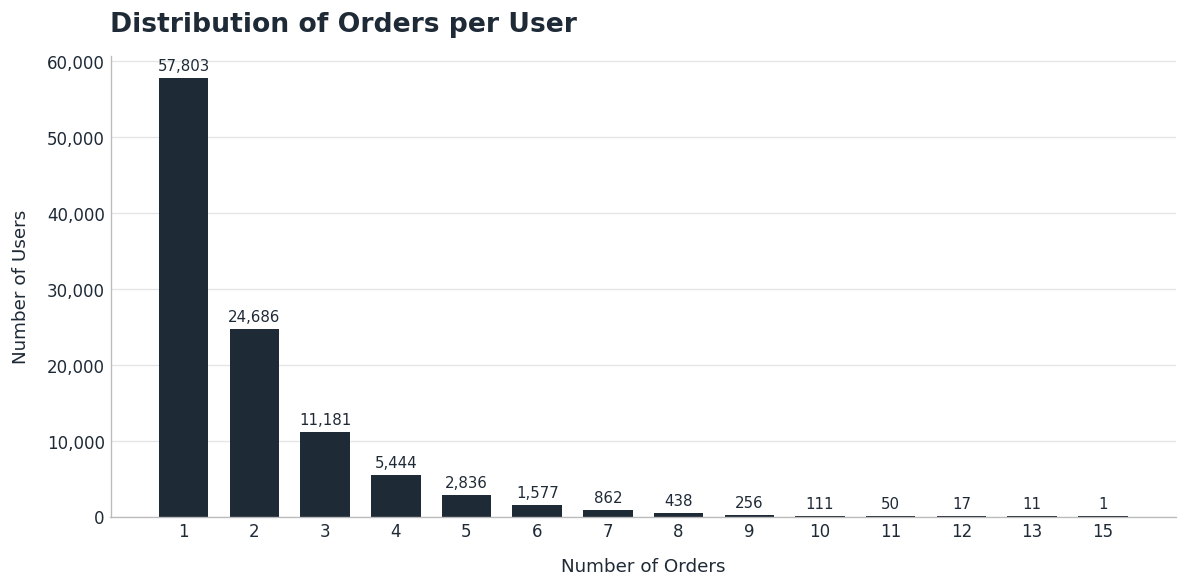

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(order_distribution.index.astype(str), order_distribution.values,
              color=dark, width=0.7)
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=9, color=dark)

style_axes(ax, "Distribution of Orders per User", "Number of Orders", "Number of Users")
thousands(ax, "y")

plt.tight_layout()
plt.show()

#### Sampling Check

The number of observed orders per user may not represent the complete purchase history of each customer.

The variable order_number indicates the position of an order within the broader customer history.

If the highest observed order_number is larger than the number of orders available for that user in this dataset, then part of the customer history is missing from the sample.

In [12]:
user_coverage = df.groupby("user_id").agg(
    observed_orders=("order_id", "nunique"),
    highest_order_number=("order_number", "max"),
)

has_gaps = user_coverage["observed_orders"] < user_coverage["highest_order_number"]
print(f"Users whose history has unobserved orders: {has_gaps.mean():.1%}")
print(f"Median highest order_number per user:       {user_coverage['highest_order_number'].median():.0f}")
print(f"Median observed orders per user:            {user_coverage['observed_orders'].median():.0f}")

Users whose history has unobserved orders: 93.6%
Median highest order_number per user:       10
Median observed orders per user:            1


### **Finding**

Observed customer coverage is sparse.

54.9% of users contribute only one observed order, while approximately 78.4% contribute two observed orders or fewer.

However, these counts do not represent complete customer histories.

For approximately **93.6% of users**, the highest observed order_number is larger than the number of orders contained in the dataset.

The median user has a maximum observed order_number of 10 while only one order is present in the sample.

This indicates that the dataset contains a partial sample of broader customer histories rather than complete longitudinal records.

Customer level department proportions therefore cannot be interpreted confidently as stable long term preferences.

### Methodological Decision

Because complete customer histories are not available, the customer is not used as the primary unit of segmentation.

Instead, each observed order is treated as a self contained shopping event.

This changes the main research question from identifying customer types to identifying recurring types of shopping events.

Customer identifiers are retained for a secondary analysis using the subset of users for whom consecutive orders are actually observed.

## 3. Order Level Basket Representation

The primary unit of analysis is now the individual grocery order.

To compare shopping missions, each order must be represented numerically according to its department composition.

Raw department counts are first calculated for each order. These counts are then converted into proportions so that orders of different sizes can be compared based on their relative composition rather than their absolute number of products.

Basket size will be retained separately as a contextual variable for later interpretation.

In [13]:
order_department_counts = df.groupby(["order_id", "department"]).size()
order_department_matrix = order_department_counts.unstack(fill_value=0)

display(order_department_matrix.head())

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
order_id,,,,,,,,,,,,,,,,,,,,,
10,0,2,0,0,0,0,1,1,0,0,...,0,0,1,0,0,0,0,0,10,0
11,0,0,0,0,0,0,1,0,1,0,...,0,0,0,0,0,1,0,0,0,1
28,0,0,0,0,0,0,0,8,0,0,...,0,0,1,0,0,1,0,0,6,0
38,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,6,1
56,0,0,0,1,0,0,1,3,0,0,...,0,0,0,0,0,1,0,0,3,0


In [14]:
# Basket size = number of products per order
order_totals = order_department_matrix.sum(axis=1)

In [15]:
order_department_proportions = order_department_matrix.div(order_totals, axis=0)

print("Orders:     ", len(order_department_proportions))
print("Departments:", order_department_proportions.shape[1])
print("All rows sum to 1:", np.allclose(order_department_proportions.sum(axis=1), 1.0))

display(order_department_proportions.head())

Orders:      200000
Departments: 21
All rows sum to 1: True


department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
order_id,,,,,,,,,,,,,,,,,,,,,
10,0.0,0.133333,0.0,0.0,0.0,0.0,0.066667,0.066667,0.0,0.0,...,0.0,0.0,0.066667,0.0,0.0,0.000000,0.0,0.0,0.666667,0.000000
11,0.0,0.000000,0.0,0.0,0.0,0.0,0.200000,0.000000,0.2,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.200000,0.0,0.0,0.000000,0.200000
28,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.500000,0.0,0.0,...,0.0,0.0,0.062500,0.0,0.0,0.062500,0.0,0.0,0.375000,0.000000
38,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.111111,0.0,0.0,0.666667,0.111111
56,0.0,0.000000,0.0,0.1,0.0,0.0,0.100000,0.300000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.100000,0.0,0.0,0.300000,0.000000


### Basket Representation

Each row now represents one complete grocery order, while each column represents a supermarket department.

The values correspond to the proportion of products in the basket belonging to each department.

For example, a value of 0.40 for produce means that 40% of the products in that order came from the produce department.

Using proportions allows baskets of different sizes to be compared based on their composition. The original basket size is retained separately for later behavioral profiling.

A validation step confirmed that the department proportions of every order sum to approximately 1.

## 4. Exploratory Analysis of Shopping Baskets

Before applying dimensionality reduction and clustering, we examine a few basic characteristics of the baskets:

- basket size,
- number of departments represented in each basket,
- and overall department prevalence.

These checks help determine whether the orders contain enough variation to support meaningful shopping mission segmentation.

### 4.1 Basket Size

Basket size describes the total number of products contained in each order.

Examining its distribution helps determine whether the dataset is dominated by very small purchases or contains a broad range of shopping-trip sizes.

In [16]:
display(order_totals.describe())

,0
count,200000.000000
mean,10.097505
std,7.539068
min,1.000000
25%,5.000000
50%,8.000000
75%,14.000000
max,137.000000


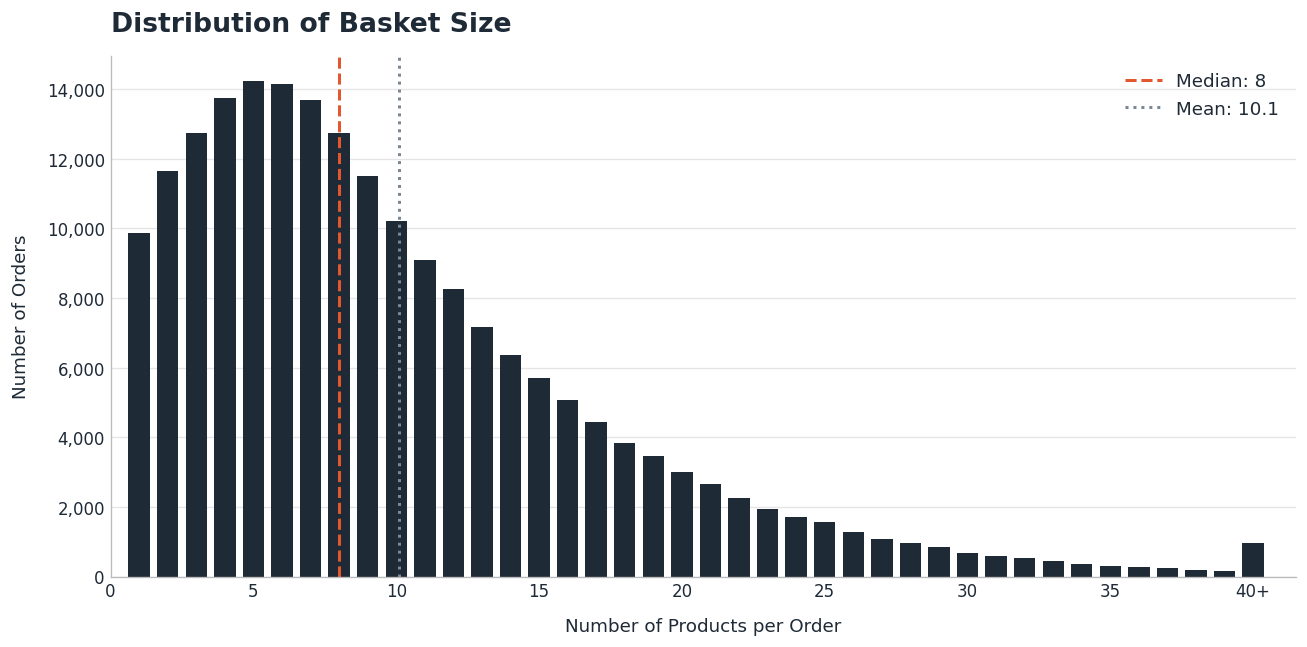

In [17]:
clipped = np.clip(order_totals, None, basket_cap)
median, mean = np.median(order_totals), np.mean(order_totals)

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.hist(clipped, bins=np.arange(0.5, basket_cap + 1.5, 1), color=dark, rwidth=0.75)
add_median_mean(ax, median, mean)

ticks = list(range(0, basket_cap + 1, 5))
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) if t < basket_cap else f"{basket_cap}+" for t in ticks])
ax.set_xlim(0, basket_cap + 1.5)

style_axes(ax, "Distribution of Basket Size", "Number of Products per Order", "Number of Orders")
thousands(ax, "y")

plt.tight_layout()
plt.show()

#### **Finding**

Basket size is strongly right skewed.

The median order contains 8 products, while the mean is approximately 10.1 products.  
75% of orders contain 14 products or fewer, although a small number of substantially larger purchases create a long right tail, with the largest observed basket containing 137 products.

This indicates that most shopping events are relatively small or medium-sized, while very large baskets are uncommon.

### 4.2 Small Basket Check

Because the clustering representation is based on department proportions, very small baskets require additional attention.

For example, a one-product order will always have 100% of its composition assigned to a single department, creating an extreme profile regardless of the broader meaning of the shopping trip.

In [18]:
small_baskets = pd.DataFrame({"Basket Size": range(1, 6)})
small_baskets["Number of Orders"] = [(order_totals == s).sum() for s in small_baskets["Basket Size"]]
small_baskets["Percentage of Orders"] = (small_baskets["Number of Orders"] / len(order_totals) * 100).round(2)
display(small_baskets)

small_basket_share = (order_totals <= small_basket_max).mean() * 100
print(f"Orders containing {small_basket_max} products or fewer: {small_basket_share:.2f}%")

,Basket Size,Number of Orders,Percentage of Orders
0,1,9866,4.93
1,2,11654,5.83
2,3,12737,6.37
3,4,13760,6.88
4,5,14242,7.12


Orders containing 3 products or fewer: 17.13%


#### **Finding**

Approximately 17.13% of all orders contain three products or fewer.

These orders are valid shopping events and may represent genuine quick or convenience purchases. However, their department-composition vectors are necessarily more extreme than those of larger baskets.

For this reason, small baskets will initially be retained, but their influence on the resulting clusters will be evaluated during model validation.

### 4.3 Department Diversity per Order

Basket size alone does not describe how varied an order is.

Two orders may contain the same number of products while covering very different numbers of departments. We therefore calculate how many distinct departments are represented in each order.

,0
count,200000.000000
mean,4.738600
std,2.552107
min,1.000000
25%,3.000000
50%,4.000000
75%,6.000000
max,16.000000


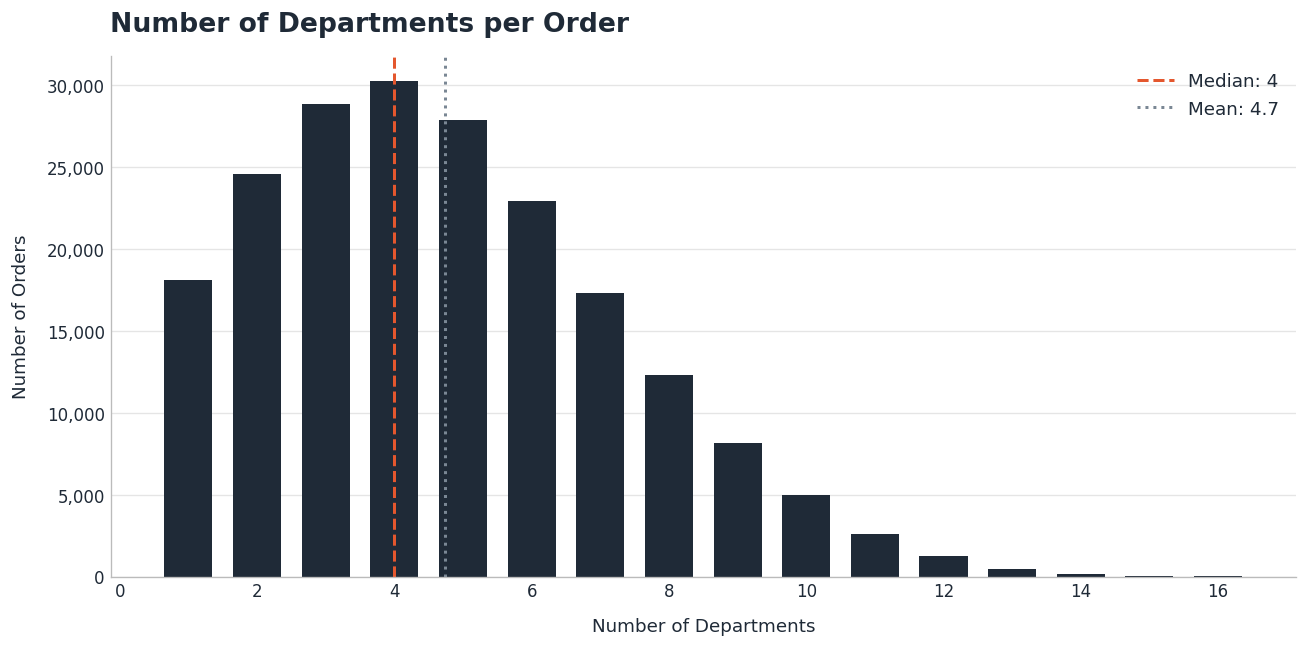

In [19]:
departments_per_order = (order_department_matrix > 0).sum(axis=1)
display(departments_per_order.describe())

counts = departments_per_order.value_counts().sort_index()
counts = counts.reindex(range(counts.index.min(), counts.index.max() + 1), fill_value=0)

median, mean = departments_per_order.median(), departments_per_order.mean()

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(counts.index, counts.values, width=0.7, color=dark)
add_median_mean(ax, median, mean)

style_axes(ax, "Number of Departments per Order", "Number of Departments", "Number of Orders")
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=12))
thousands(ax, "y")

plt.tight_layout()
plt.show()

#### **Finding**

Orders typically involve a limited subset of the 21 available supermarket departments.

The median basket contains products from 4 departments, while 75% of orders contain products from 6 departments or fewer out of the 21 available.

At the same time, most baskets are not restricted to a single department. The highest concentration occurs around combinations of roughly 3 to 6 departments per order.

This suggests that baskets may contain enough compositional variation to support the identification of distinct shopping missions.

### 4.4 Overall Department Prevalence

Before applying dimensionality reduction, we examine how frequently each department appears across shopping baskets.

Department prevalence is defined as the percentage of orders containing at least one product from a given department.

This helps identify departments that are nearly universal across purchases as well as departments associated with more specialized shopping missions.

In [20]:
department_prevalence = (
    (order_department_matrix > 0).mean(axis=0).mul(100).sort_values(ascending=False)
)

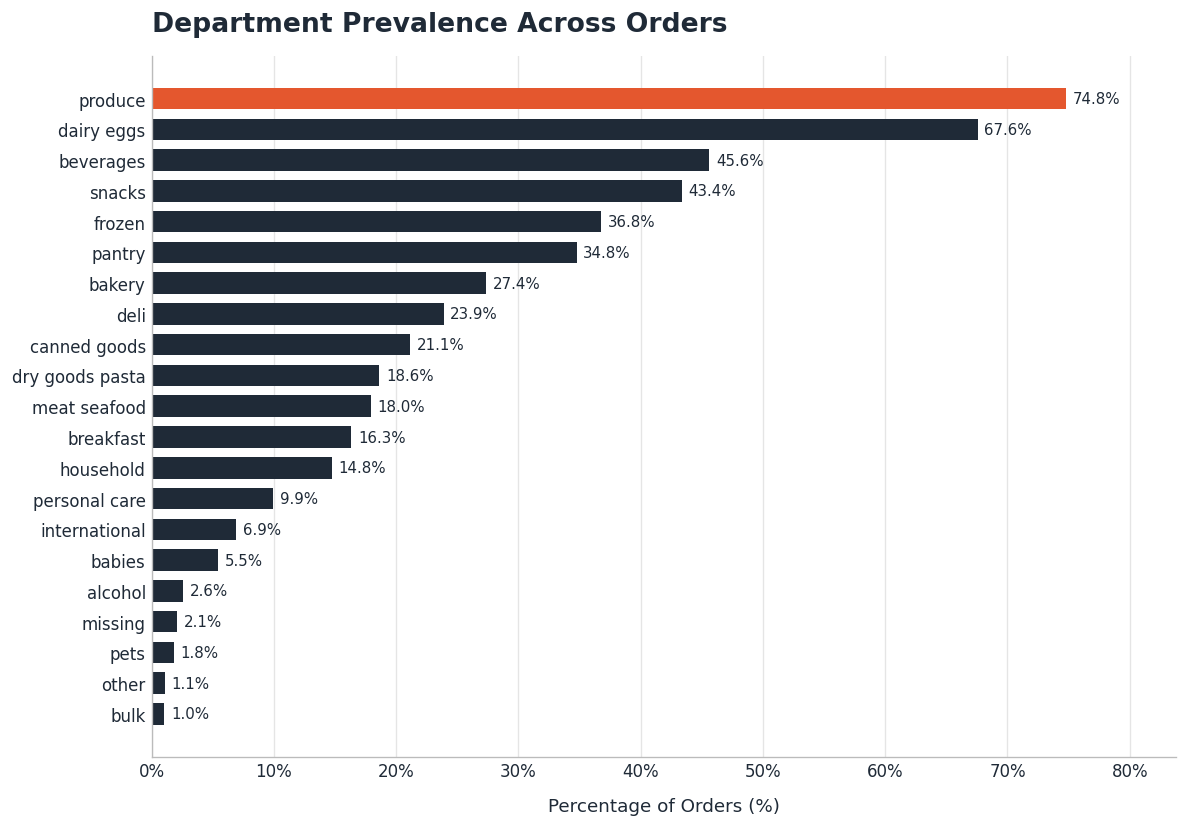

In [21]:
barh_chart(department_prevalence, "Department Prevalence Across Orders", "Percentage of Orders (%)")

#### **Finding**

Department prevalence varies substantially across shopping baskets.

produce and dairy eggs are the most widespread departments, appearing in a large majority of orders, while departments such as pets, other, and bulk occur much less frequently.

Importantly, no department appears in virtually every order. This indicates that department presence still varies considerably across baskets, leaving room for different combinations of departments to characterize distinct shopping missions.

### 4.5 Average Department Share

Department prevalence indicates how often a department appears, but it does not show how much of the basket that department typically represents.

To complement prevalence, we calculate the average proportion of each order assigned to each department.

Because this calculation includes orders in which a department is absent, it reflects the average contribution of each department

In [22]:
average_department_share = (
    order_department_proportions.mean(axis=0).mul(100).sort_values(ascending=False)
)

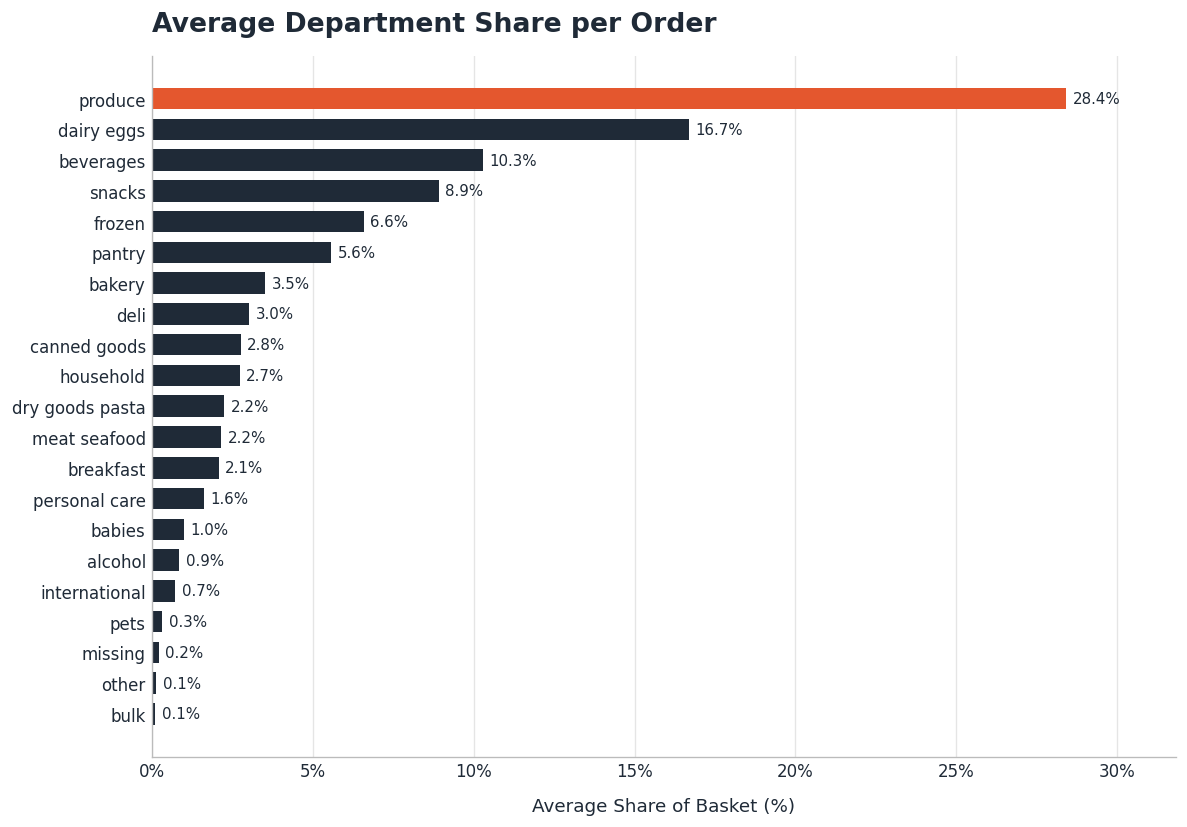

In [23]:
barh_chart(average_department_share, "Average Department Share per Order", "Average Share of Basket (%)")

#### **Finding**

The ranking of average basket share broadly follows department prevalence.

produce, dairy eggs, and beverages remain among the most important departments, suggesting that the most frequently observed departments also account for a substantial proportion of the average basket.

However, this measure includes zero values from orders in which a department is absent. As a result, less frequent departments may appear unimportant even if they represent a substantial portion of the basket when they do occur.

### 4.6 Department Importance When Present

To distinguish frequency from within-basket importance, department shares are recalculated only among orders in which each department is present.

This makes it possible to identify departments that occur infrequently but become an important part of the basket when they do appear.

In [24]:
average_share_when_present = (
    order_department_proportions.replace(0, np.nan).mean(axis=0).mul(100).sort_values(ascending=False)
)

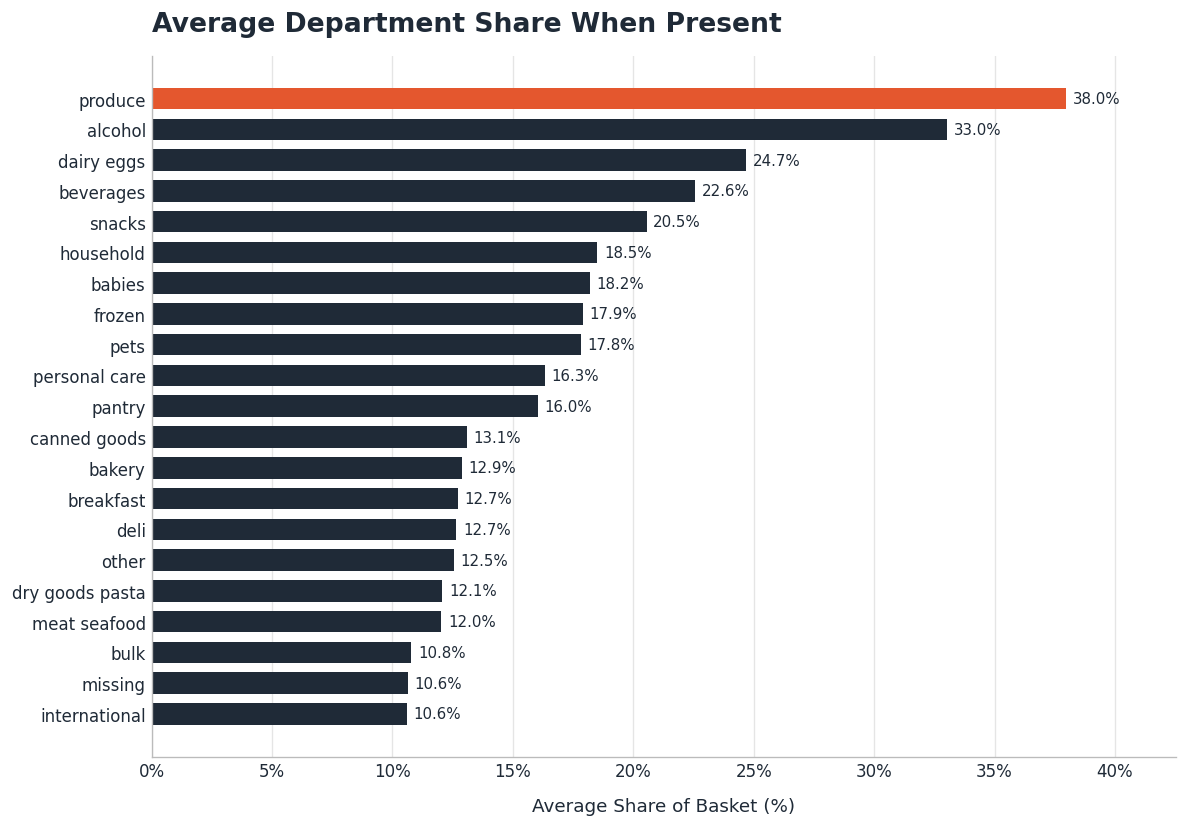

In [25]:
barh_chart(average_share_when_present, "Average Department Share When Present", "Average Share of Basket (%)")

#### **Finding**

Department prevalence and within-basket importance reveal different purchasing patterns.

produce is both highly prevalent and dominant when present, suggesting that it acts as a broad component of many grocery orders.

In contrast, departments such as alcohol, babies, and pets occur in substantially fewer orders but can represent a meaningful share of the basket when they do appear.

This distinction suggests that low-prevalence departments should not automatically be treated as unimportant, since they may provide useful information for identifying more specialized shopping patterns.

## 5. Preparing Basket Composition for Modeling

The order-level feature matrix consists of department proportions.

This representation is appropriate for comparing basket composition independently of basket size, but it introduces an important statistical constraint: the department proportions of every order sum to 1.

As a result, the features are not completely independent. Increasing the relative share of one department necessarily reduces the share available to the others, which can influence correlations, distances, and dimensionality-reduction methods such as PCA.

The data are also sparse because most orders contain products from only a subset of the 21 available departments.

Before clustering, two representations are therefore compared:

1. the original department proportions,
2. a Hellinger transformed representation.

### 5.1 Hellinger Transformation

The Hellinger transformation applies the square root to each department proportion.

This reduces the dominance of departments with very large basket shares while increasing the relative influence of smaller components.

It also preserves zero values, making it suitable for the sparse basket representation without requiring arbitrary zero replacement.

The transformation is defined as:

$$
h_{ij} = \sqrt{p_{ij}}
$$

where $$p_{ij}$$ is the proportion of department $$j$$ in order $$i$$

The Hellinger transformation is used here as a pragmatic representation for sparse proportional data. It does not eliminate every issue associated with compositional data, but it provides a zero preserving alternative whose effect can be evaluated empirically against the raw representation.

In [26]:
hellinger_proportions = np.sqrt(order_department_proportions)

hellinger_norms = np.sqrt((hellinger_proportions ** 2).sum(axis=1))
print("All Hellinger-transformed rows have unit norm:", np.allclose(hellinger_norms, 1.0))

All Hellinger-transformed rows have unit norm: True


#### **Finding**

Each transformed order has unit Euclidean norm.

Unlike the original proportions, the transformed values no longer sum to 1. Instead, the squared transformed values sum to 1, changing the geometry of the feature space while preserving the original basket composition information.

### 5.2 Comparing Raw and Hellinger Representations with PCA

Rather than adopting the transformation solely on theoretical grounds, PCA is applied to both the raw and Hellinger transformed representations.

The comparison focuses on two questions:

1. Does Hellinger substantially change the principal structure of the data?
2. Does it reduce the concentration of variance in a small number of dominant directions?

PCA is applied without standardization. All department features originate from the same proportional scale, and standardizing each feature to unit variance could disproportionately amplify rare departments.

In [27]:
pca_raw = PCA()
raw_pca_scores = pca_raw.fit_transform(order_department_proportions)

pca_hellinger = PCA()
hellinger_pca_scores = pca_hellinger.fit_transform(hellinger_proportions)

In [28]:
pca_comparison = pd.DataFrame({
    "Principal Component": range(1, len(pca_raw.explained_variance_ratio_) + 1),
    "Raw Explained Variance": pca_raw.explained_variance_ratio_,
    "Hellinger Explained Variance": pca_hellinger.explained_variance_ratio_,
})
pca_comparison["Raw Cumulative Variance"] = pca_comparison["Raw Explained Variance"].cumsum()
pca_comparison["Hellinger Cumulative Variance"] = pca_comparison["Hellinger Explained Variance"].cumsum()

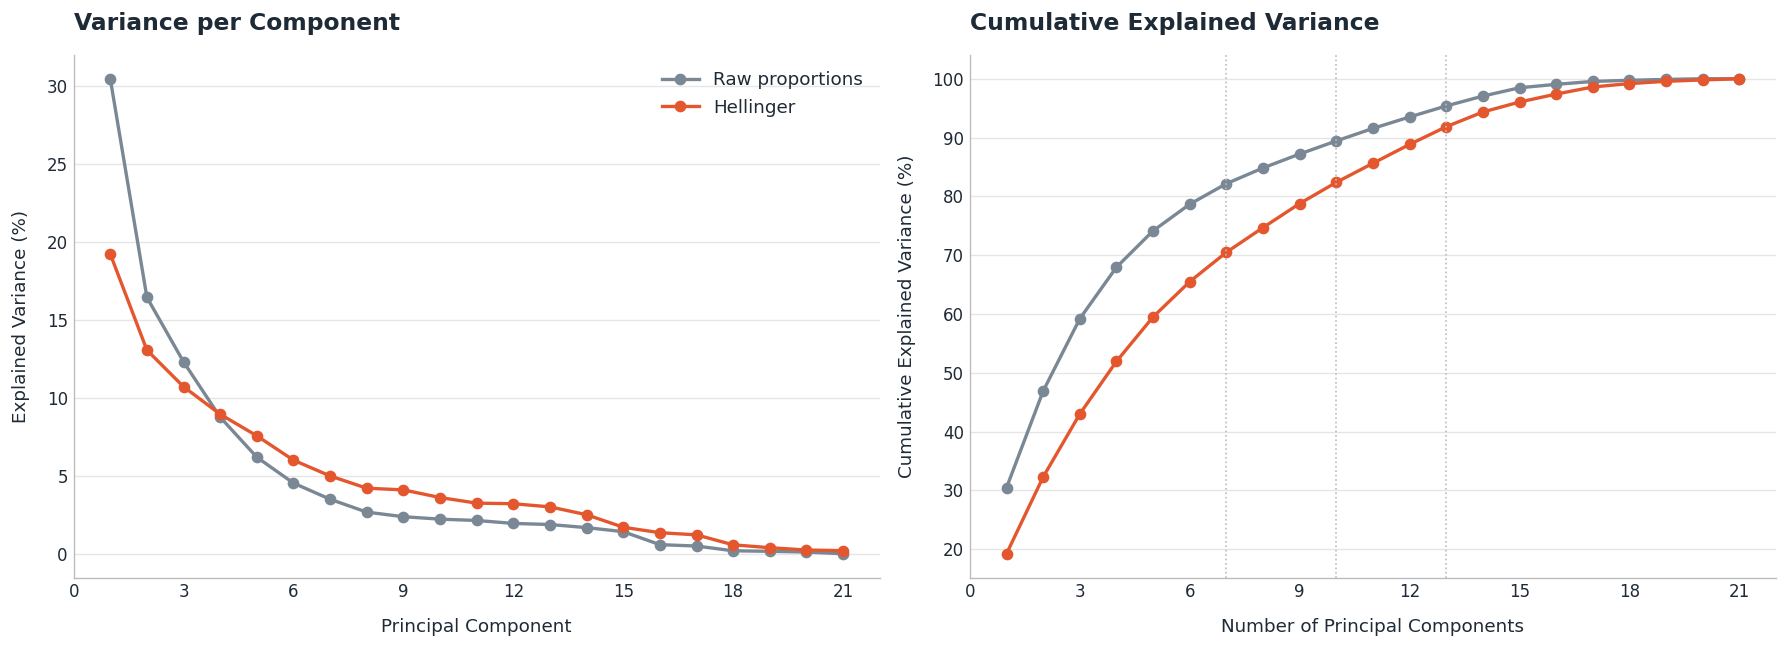

In [29]:
pcs = pca_comparison["Principal Component"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for label, col in [("Raw proportions", "Raw Explained Variance"),
                   ("Hellinger", "Hellinger Explained Variance")]:
    axes[0].plot(pcs, pca_comparison[col] * 100, marker="o", linewidth=2,
                 color=representation_colors[label], label=label)
style_axes(axes[0], "Variance per Component", "Principal Component",
           "Explained Variance (%)", title_size=14)

for label, col in [("Raw proportions", "Raw Cumulative Variance"),
                   ("Hellinger", "Hellinger Cumulative Variance")]:
    axes[1].plot(pcs, pca_comparison[col] * 100, marker="o", linewidth=2,
                 color=representation_colors[label], label=label)
for n in pc_candidates:
    axes[1].axvline(n, color=spine, linestyle=":", linewidth=1)
style_axes(axes[1], "Cumulative Explained Variance", "Number of Principal Components",
           "Cumulative Explained Variance (%)", title_size=14)

for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

plt.tight_layout()
plt.show()

#### **Finding**

PCA reveals a clear difference in how variance is distributed between the two representations.

The first principal component explains approximately **30.45%** of the variance in the raw department proportions, compared with **19.22%** after the Hellinger transformation.

The first three components account for approximately:

- **59.19%** of variance using raw proportions,
- **42.99%** using Hellinger-transformed proportions.

Approximately 82% of the variance is retained with 7 components in the raw representation and 10 components in the Hellinger representation.

This indicates that the raw representation concentrates considerably more variation in the first few directions, while the Hellinger transformation distributes information more broadly across components.

### 5.3 Structural Stability of the Transformation

Reducing the dominance of high-proportion departments is useful only if the transformation does not completely redefine the underlying structure of the baskets.

To evaluate this, the department loadings of corresponding principal components are compared between the raw and Hellinger representations.

Because the sign of a principal component is arbitrary, absolute loading correlations are used.

In [30]:
def loadings_table(pca_model, columns):
    return pd.DataFrame(
        pca_model.components_.T,
        index=columns,
        columns=[f"PC{i + 1}" for i in range(len(pca_model.components_))],
    )

raw_loadings = loadings_table(pca_raw, order_department_proportions.columns)
hellinger_loadings = loadings_table(pca_hellinger, hellinger_proportions.columns)

In [31]:
n_compare = 5

component_similarity = pd.DataFrame({
    "Component": [f"PC{i + 1}" for i in range(n_compare)],
    "Absolute Loading Correlation": [
        abs(np.corrcoef(raw_loadings.iloc[:, i], hellinger_loadings.iloc[:, i])[0, 1])
        for i in range(n_compare)
    ],
})
display(component_similarity.round(3))

,Component,Absolute Loading Correlation
0,PC1,0.965
1,PC2,0.965
2,PC3,0.989
3,PC4,0.989
4,PC5,0.990


#### **Finding**

The first five principal components remain highly similar across both representations.

The absolute correlations between corresponding loading vectors range from approximately **0.965 to 0.990**.

This suggests that the Hellinger transformation does not fundamentally replace the main structure found in the raw data. Instead, it largely preserves the same principal directions while redistributing variance more evenly across them.

Based on this comparison, the Hellinger representation is selected for the main clustering analysis.

### 5.4 PCA Representation for Clustering

PCA is used to create a lower-dimensional representation of the Hellinger-transformed basket data before clustering.

Because there is no sharp cutoff in cumulative explained variance, the number of components is not selected using an arbitrary threshold alone.

Three candidate representations are evaluated:

- 7 principal components,
- 10 principal components,
- 13 principal components.

These retain approximately 70%, 82%, and 92% of the total Hellinger-space variance, respectively.

The final choice will consider both statistical cluster quality and the interpretability of the resulting shopping missions.

In [32]:
pca_candidates = {}

for n_components in pc_candidates:
    pca_model = PCA(n_components=n_components)
    scores = pca_model.fit_transform(hellinger_proportions)
    pca_candidates[n_components] = {"model": pca_model, "scores": scores}
    print(f"{n_components:>2} PCs: {pca_model.explained_variance_ratio_.sum():.2%} variance retained")

 7 PCs: 70.48% variance retained
10 PCs: 82.38% variance retained
13 PCs: 91.84% variance retained


## 6. Shopping Mission Clustering

K-Means clustering is used to identify recurring shopping patterns in the PCA representation of the Hellinger-transformed basket compositions.

Because both the number of retained principal components and the number of clusters may influence the resulting segmentation, multiple configurations are evaluated rather than selecting these values arbitrarily.

Three PCA representations are compared:

- 7 components,
- 10 components,
- 13 components.

For each representation, K-Means models with between 2 and 10 clusters are evaluated using:

- silhouette score,
- inertia,
- cluster-size balance.

Silhouette scores are estimated from a reproducible sample of 10,000 orders to reduce computational cost, while K-Means itself is fitted using the complete dataset.

### 6.1 Model Configuration Search

The clustering configuration is evaluated across multiple levels of dimensionality reduction and cluster granularity.

K-Means is fitted using the complete dataset for each combination of:

- 7, 10, and 13 principal components,
- 2 through 10 clusters.

Three complementary diagnostics are considered:

- **Silhouette score:** measures cluster cohesion and separation.
- **Inertia:** measures within cluster dispersion.
- **Cluster-size balance:** helps identify solutions that rely on extremely small or disproportionately large clusters.

Because an exact silhouette calculation is computationally expensive for 200,000 observations, the score is estimated from a reproducible sample of 10,000 orders. K-Means itself is still fitted using the full dataset.

Because inertia depends on the dimensionality of the feature space, absolute inertia values are interpreted only within each PCA representation.

In [33]:
clustering_results = []

for n_components in pc_candidates:
    x_pca = pca_candidates[n_components]["scores"]

    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=random_state, n_init=10)
        labels = kmeans.fit_predict(x_pca)

        sizes = pd.Series(labels).value_counts(normalize=True)
        clustering_results.append({
            "PCA Components": n_components,
            "k": k,
            "Silhouette": silhouette_score(x_pca, labels, sample_size=silhouette_sample,
                                           random_state=random_state),
            "Inertia": kmeans.inertia_,
            "Smallest Cluster %": sizes.min() * 100,
            "Largest Cluster %": sizes.max() * 100,
        })

clustering_results = pd.DataFrame(clustering_results)
display(clustering_results.round(3))

,PCA Components,k,Silhouette,Inertia,Smallest Cluster %,Largest Cluster %
0,7,2,0.210,63294.513,37.970,62.030
1,7,3,0.143,56680.802,23.879,42.346
2,7,4,0.150,51778.965,13.896,42.562
3,7,5,0.161,47534.812,10.056,36.480
4,7,6,0.163,44393.732,9.144,29.344
5,7,7,0.171,41372.455,7.206,26.041
6,7,8,0.172,39094.895,6.423,19.388
7,7,9,0.172,37163.124,5.049,17.436
8,7,10,0.172,35325.196,4.082,17.606
9,10,2,0.188,76497.807,37.138,62.862


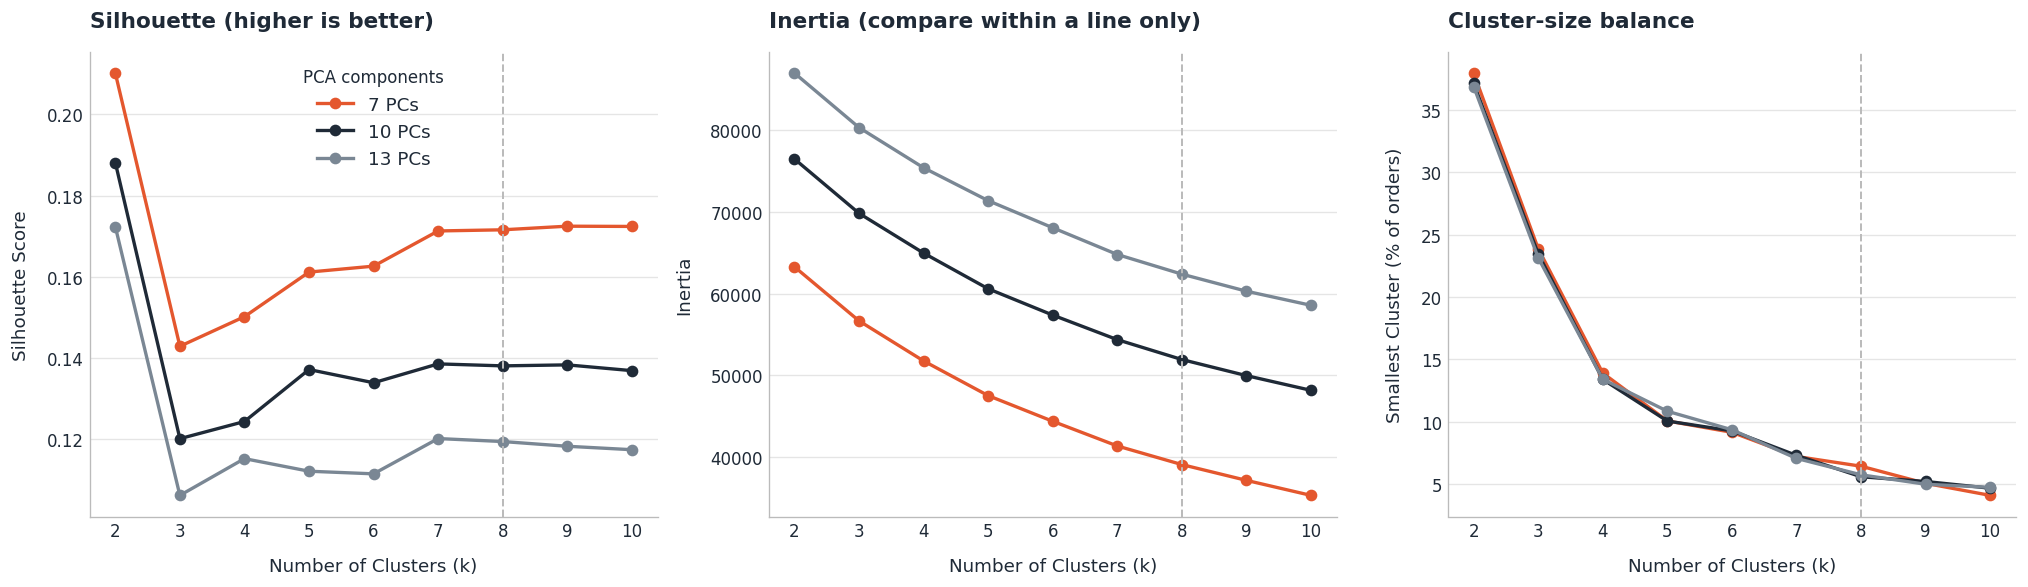

In [34]:
panels = [
    ("Silhouette",         "Silhouette Score",                   "Silhouette (higher is better)"),
    ("Inertia",            "Inertia",                            "Inertia (compare within a line only)"),
    ("Smallest Cluster %", "Smallest Cluster (% of orders)",     "Cluster-size balance"),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)

for ax, (col, ylabel, title) in zip(axes, panels):
    for n_components in pc_candidates:
        subset = clustering_results[clustering_results["PCA Components"] == n_components]
        ax.plot(subset["k"], subset[col], marker="o", linewidth=2,
                color=pc_colors[n_components], label=f"{n_components} PCs")
    ax.axvline(final_k, color=spine, linestyle="--", linewidth=1.2)   # selected k
    style_axes(ax, title, "Number of Clusters (k)", ylabel, title_size=13)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

axes[0].legend(title="PCA components")

plt.tight_layout()
plt.show()

#### **Finding**

The 7 component PCA representation consistently produces higher silhouette scores than the 10 and 13 component alternatives.

Although the two cluster solution achieves the highest silhouette score, it represents a very coarse partition of the shopping behavior.

Within the 7 component representation, silhouette performance improves again as additional clusters are introduced and reaches a plateau around 7–10 clusters.

At this point, additional clusters provide almost no improvement in geometric separation.

Because silhouette values remain modest overall, model selection cannot rely on a single metric. Solutions near the plateau are therefore evaluated in the original department space to determine whether the additional clusters represent meaningful shopping patterns rather than arbitrary fragmentation.

### 6.2 Comparing Candidate Cluster Solutions

The 6, 7, and 8 cluster solutions are examined in greater detail.

Although clustering is performed in PCA space, interpretation is carried out using the original department proportions.

For each cluster, its average department composition is compared with the overall average basket composition.

This reveals which departments are unusually prominent within each shopping pattern.

In [35]:
primary_scores = pca_candidates[final_pcs]["scores"]

candidate_models = {}
candidate_labels = {}
candidate_profiles = {}

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=final_n_init
    )

    labels = pd.Series(
        model.fit_predict(primary_scores),
        index=order_department_proportions.index,
        name="Cluster"
    )

    candidate_models[k] = model
    candidate_labels[k] = labels

    candidate_profiles[k] = (
        order_department_proportions
        .assign(Cluster=labels)
        .groupby("Cluster")
        .mean()
        .mul(100)
    )

primary_labels = candidate_labels[final_k]
primary_profile = candidate_profiles[final_k]
cluster_ids = list(primary_profile.index)

In [36]:
overall_department_share = average_department_share

def summarize_candidate(k, top_n=3):
    profile = candidate_profiles[k]
    sizes = candidate_labels[k].value_counts(normalize=True).sort_index().mul(100)

    rows = []
    for cluster in profile.index:
        top = (profile.loc[cluster] - overall_department_share).sort_values(ascending=False).head(top_n)
        rows.append({
            "k": k,
            "Cluster": cluster,
            "Cluster Size (%)": sizes.loc[cluster],
            "Most Overrepresented Departments": ", ".join(f"{d} (+{v:.1f} pp)" for d, v in top.items()),
        })
    return pd.DataFrame(rows)


candidate_summary = pd.concat([summarize_candidate(k) for k in candidate_ks], ignore_index=True)
display(candidate_summary.round({"Cluster Size (%)": 1}))

,k,Cluster,Cluster Size (%),Most Overrepresented Departments
0,6,0,28.2,"produce (+11.1 pp), dairy eggs (+8.8 pp), cann..."
1,6,1,23.1,"frozen (+13.8 pp), dry goods pasta (+0.7 pp), ..."
2,6,2,14.5,"produce (+37.6 pp), canned goods (+0.3 pp), me..."
3,6,3,12.1,"dairy eggs (+15.8 pp), household (+6.7 pp), pa..."
4,6,4,13.1,"snacks (+29.5 pp), beverages (+1.2 pp), breakf..."
5,6,5,9.1,"beverages (+44.3 pp), household (+1.8 pp), per..."
6,7,0,8.8,"dairy eggs (+33.8 pp), bakery (+0.9 pp), break..."
7,7,1,7.8,"beverages (+48.0 pp), household (+0.9 pp), alc..."
8,7,2,22.9,"frozen (+13.1 pp), dry goods pasta (+0.6 pp), ..."
9,7,3,13.8,"produce (+38.9 pp), canned goods (+0.2 pp), me..."


#### **Finding**

The candidate solutions show a gradual transition from broader groups toward more differentiated basket profiles.

Moving from 6 to 7 clusters separates a broader mixed pattern into more distinct dairy focused and household/pantry oriented profiles.

The 8 cluster solution introduces an additional pattern with elevated pantry, produce, canned goods, and dry goods pasta.

This additional profile remains interpretable in the original department space.

The 8 cluster solution also maintains approximately the same silhouette performance as the 7 cluster solution while reducing the concentration of orders in the largest cluster.

For these reasons, the 8 cluster solution is chosen.

### 6.3 Comparison with a Dominant-Department Baseline

A clustering model would provide limited additional insight if its groups simply reproduced the department with the largest share in each basket.

To evaluate this possibility, each order is assigned a simple baseline label corresponding to its dominant department.

The dominant-department composition of each cluster is then examined.

If a cluster contains orders with several different dominant departments, the clustering is capturing a broader multi-department structure rather than merely reproducing the largest department.

In [37]:
max_department_share = order_department_proportions.max(axis=1)
n_tied = order_department_proportions.eq(max_department_share, axis=0).sum(axis=1)

dominant_baseline = pd.DataFrame({
    "Cluster": primary_labels,
    "Dominant Department": order_department_proportions.idxmax(axis=1),
    "Is Tie": n_tied > 1,
})

tie_share_by_cluster = dominant_baseline.groupby("Cluster")["Is Tie"].mean().mul(100)

unique_dominant = dominant_baseline[~dominant_baseline["Is Tie"]]
dominant_by_cluster = (
    pd.crosstab(unique_dominant["Cluster"], unique_dominant["Dominant Department"], normalize="index")
    .mul(100)
)

dominant_summary = pd.DataFrame({
    "Most Common Dominant Department": dominant_by_cluster.idxmax(axis=1),
    "Share Among Unique Dominant Orders (%)": dominant_by_cluster.max(axis=1),
    "Tied Dominant Department (%)": tie_share_by_cluster,
})
display(dominant_summary.round(1))

print(f"Orders with tied dominant departments: {(n_tied > 1).mean() * 100:.2f}%")

,Most Common Dominant Department,Share Among Unique Dominant Orders (%),Tied Dominant Department (%)
Cluster,,,
0,dairy eggs,87.8,26.4
1,produce,98.1,7.3
2,frozen,34.5,34.8
3,household,28.1,25.1
4,produce,77.2,19.2
5,snacks,72.5,35.8
6,beverages,92.6,24.5
7,produce,72.2,20.7


Orders with tied dominant departments: 23.63%


#### **Finding**

Approximately **23.6%** of orders contain a tie for the largest department share, which makes a simple dominant department rule ambiguous for a substantial part of the dataset.

Among orders with a unique dominant department, some clusters are highly focused.

produce is dominant in approximately **98.1%** of uniquely dominated Cluster 1 orders, while beverages is dominant in approximately **92.6%** of Cluster 6 orders.

Department dominance does not uniquely determine cluster membership.

Clusters 1, 4, and 7 all have produce as their most common dominant department, but their broader basket profiles differ substantially.

Other clusters are much more heterogeneous. For example, the most common dominant department represents only **34.5%** of uniquely dominated Cluster 2 orders and **28.1%** of Cluster 3 orders.

The clustering therefore captures structure beyond assigning each basket to its largest department.

### 6.4 Cluster Profiles

To visualize what distinguishes each shopping mission, the average department composition of each cluster is compared with the overall basket composition.

Positive values indicate that a department is overrepresented within a cluster relative to the typical order.

Negative values indicate underrepresentation.

In [38]:
department_order = overall_department_share.sort_values(ascending=False).index

profile_difference = (primary_profile - overall_department_share)[department_order]
cluster_share = primary_labels.value_counts(normalize=True).mul(100)

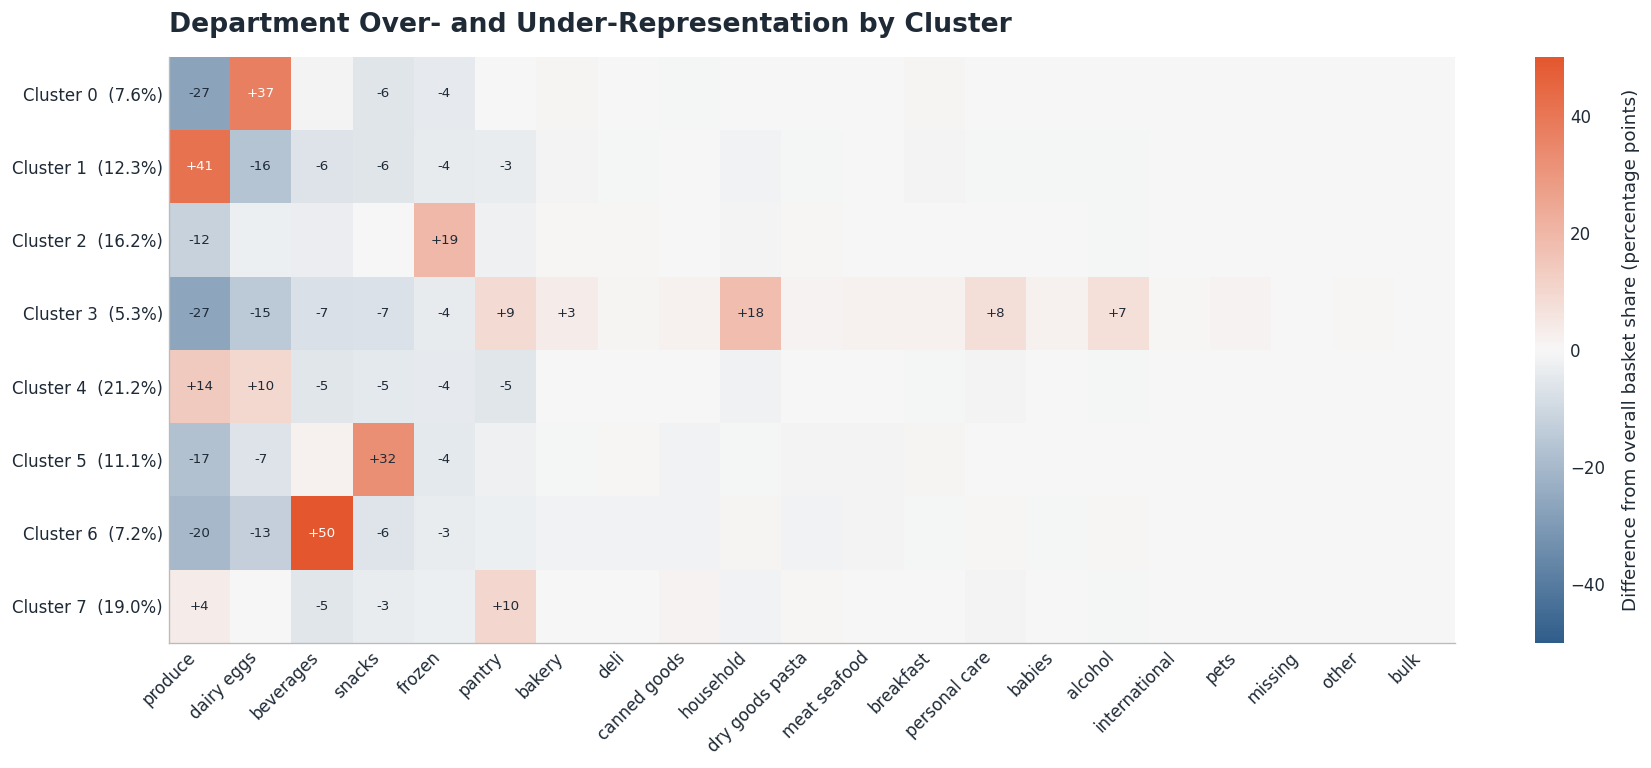

In [39]:
max_abs = np.abs(profile_difference.to_numpy()).max()

fig, ax = plt.subplots(figsize=(15, 6.5))

im = annotated_heatmap(ax, profile_difference, cmap_diverging,
                       vmin=-max_abs, vmax=max_abs, fmt="{:+.0f}", min_abs=3)

ax.set_xticks(range(profile_difference.shape[1]))
ax.set_xticklabels(profile_difference.columns, rotation=45, ha="right")
ax.set_yticks(range(profile_difference.shape[0]))
ax.set_yticklabels([f"{cluster_label(c)}  ({cluster_share[c]:.1f}%)" for c in profile_difference.index])
ax.set_title("Department Over- and Under-Representation by Cluster")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Difference from overall basket share (percentage points)")
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

#### **Finding**

The final cluster profiles reveal both specialized and composite basket structures.

Some missions are strongly concentrated around individual departments, particularly produce, beverages, and dairy eggs.

Other clusters are characterized by combinations of departments, including patterns involving produce and pantry, produce and dairy eggs, and broader baskets containing elevated shares of frozen, household, and personal care.

These mixed profiles support the interpretation of the segmentation as recurring shopping patterns rather than a simple ranking of dominant departments.

### 6.5 Cluster Size and PCA Projection

The cluster size distribution provides a simple check for extreme imbalance.

The PCA map shows a two dimensional projection of the selected solution.

Only the first two principal components are displayed, which together explain approximately 32% of the variance in the Hellinger representation.

The figure therefore provides a partial view of the clustering structure rather than a complete representation of the seven dimensional space used by K Means.

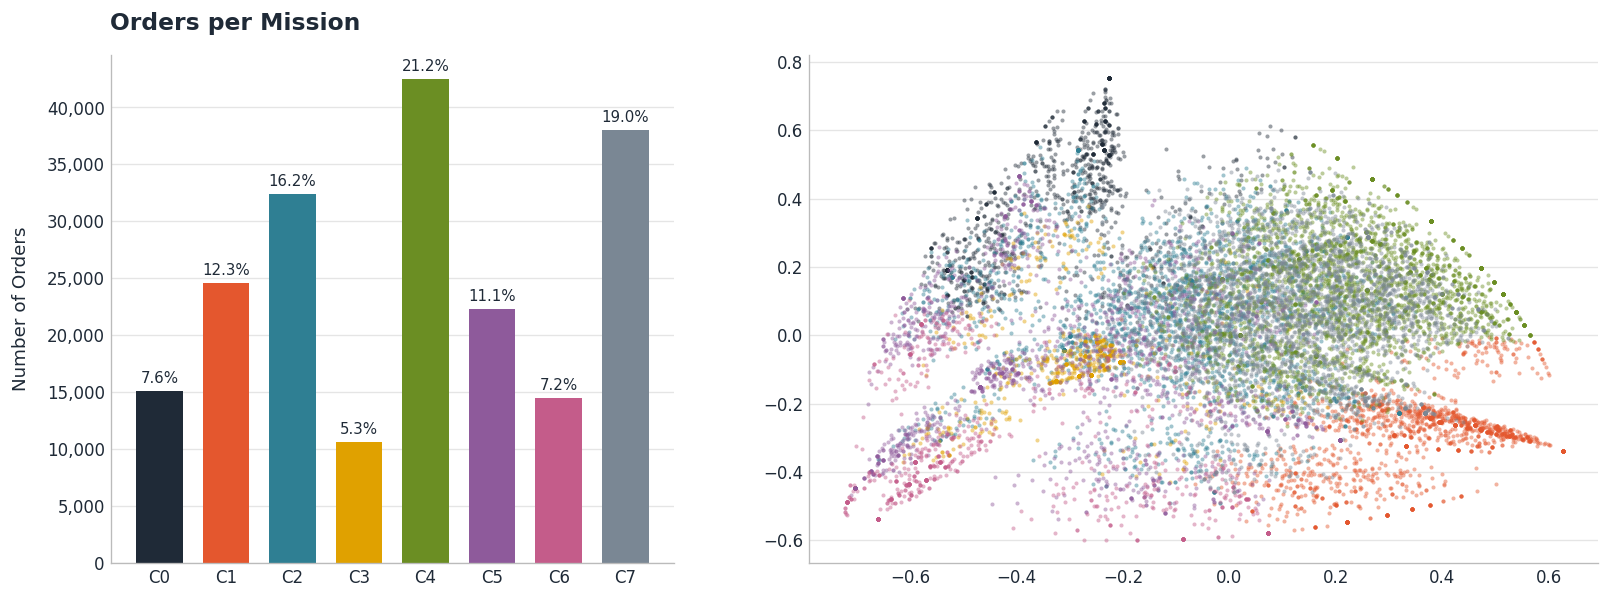

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

# Left: cluster sizes
sizes = primary_labels.value_counts().sort_index()
bars = axes[0].bar([cluster_label(c, short=True) for c in sizes.index], sizes.values,
                   color=[cluster_color(c) for c in sizes.index], width=0.7)
axes[0].bar_label(bars, labels=[f"{v / len(primary_labels):.1%}" for v in sizes.values],
                  padding=3, fontsize=9, color=dark)
style_axes(axes[0], "Orders per Mission", "", "Number of Orders", title_size=14)
thousands(axes[0], "y")

# Right: PC1 vs PC2 on a reproducible sample
plot_idx = np.random.RandomState(random_state).choice(
    len(primary_scores),
    size=min(15_000, len(primary_scores)),
    replace=False
)

for c in cluster_ids:
    mask = primary_labels.to_numpy()[plot_idx] == c

    axes[1].scatter(
        primary_scores[plot_idx][mask, 0],
        primary_scores[plot_idx][mask, 1],
        s=6,
        alpha=0.45,
        color=cluster_color(c),
        label=cluster_label(c),
        linewidths=0
    )

### 6.6 Primary Model Selection

Based on the combined statistical and interpretive evaluation, the primary shopping-mission model uses:

- **Hellinger-transformed department proportions**
- **7 principal components**
- **8 K-Means clusters**

The 7 component PCA representation provides the strongest cluster separation among the dimensionality-reduction alternatives tested.

Within this representation, silhouette performance reaches a plateau around 7 to 10 clusters.

The 8 cluster solution is selected because it preserves approximately the same geometric separation as nearby alternatives while producing a more balanced and interpretable set of basket profiles.

Importantly, comparison with the dominant department baseline shows that several clusters contain substantial variation in their dominant departments, indicating that the model captures multi department shopping patterns in addition to highly specialized trips.

The silhouette score remains modest, so these groups should be interpreted as recurring and overlapping shopping profiles rather than perfectly separated natural categories.

The selected configuration is treated as the primary model and is evaluated further through robustness checks before interpretation.

## 7. Robustness Checks

The primary segmentation was selected using Hellinger transformed department proportions, seven principal components, and eight K Means clusters.

Before interpreting these groups as shopping missions, three robustness checks are performed:

1. clustering directly on the full Hellinger representation without PCA,
2. repeating the PCA and K Means pipeline after excluding baskets containing three products or fewer,
3. repeating the final model across several random seeds.

These tests evaluate whether the identified structure depends excessively on dimensionality reduction, very small baskets, or one favorable centroid initialization.

### 7.1 PCA Sensitivity

The primary model performs clustering in a seven-component PCA representation.

To determine whether PCA is necessary for the observed structure, an eight cluster K-Means model is also fitted directly to the 21 Hellinger transformed department features.

The resulting partitions are compared using the Adjusted Rand Index, which evaluates agreement between cluster assignments while remaining invariant to arbitrary cluster labels.

In [41]:
direct_kmeans = KMeans(
    n_clusters=final_k,
    random_state=random_state,
    n_init=final_n_init
)
direct_labels = pd.Series(direct_kmeans.fit_predict(hellinger_proportions),
                          index=hellinger_proportions.index, name="Direct Cluster")

ari_direct = adjusted_rand_score(primary_labels, direct_labels)
print(f"Adjusted Rand Index (PCA vs direct Hellinger clustering): {ari_direct:.3f}")

Adjusted Rand Index (PCA vs direct Hellinger clustering): 0.469


In [42]:
direct_silhouette = silhouette_score(hellinger_proportions, direct_labels,
                                     sample_size=silhouette_sample, random_state=random_state)
pca_silhouette = silhouette_score(
    primary_scores,
    primary_labels,
    sample_size=silhouette_sample,
    random_state=random_state
)

print(f"Silhouette, direct Hellinger ({hellinger_proportions.shape[1]} features): {direct_silhouette:.3f}")
print(f"Silhouette, PCA ({final_pcs} components):            {pca_silhouette:.3f}")

Silhouette, direct Hellinger (21 features): 0.107
Silhouette, PCA (7 components):            0.171


#### **Finding**

Clustering directly on the 21 Hellinger transformed department features produced a silhouette score of approximately **0.107**, compared with **0.171** for the seven component PCA representation.

The two solutions showed partial agreement, with an Adjusted Rand Index of **0.469**.

This indicates that some of the underlying basket structure is shared across both representations, while PCA provides a feature space in which K Means achieves clearer geometric separation.

PCA is therefore retained in the primary modeling pipeline.

### 7.2 Small-Basket Sensitivity

Orders containing three products or fewer represent approximately 17.1% of the dataset.

Because the composition of these baskets is highly sensitive to individual products, the complete PCA + K-Means pipeline is repeated after excluding them.

The resulting cluster assignments and profiles are compared with the primary model to determine whether the identified shopping patterns persist independently of very small baskets.

In [43]:
large_basket_mask = order_totals > small_basket_max
hellinger_without_small = hellinger_proportions.loc[large_basket_mask]

print(f"Orders retained:     {len(hellinger_without_small):,}")
print(f"Percentage retained: {len(hellinger_without_small) / len(hellinger_proportions):.2%}")

Orders retained:     165,743
Percentage retained: 82.87%


In [44]:
pca_without_small = PCA(n_components=final_pcs)
scores_without_small = pca_without_small.fit_transform(hellinger_without_small)

print(f"Variance retained without small baskets: {pca_without_small.explained_variance_ratio_.sum():.2%}")

Variance retained without small baskets: 68.26%


In [45]:
kmeans_without_small = KMeans(
    n_clusters=final_k,
    random_state=random_state,
    n_init=final_n_init
)
labels_without_small = pd.Series(kmeans_without_small.fit_predict(scores_without_small),
                                 index=hellinger_without_small.index, name="Cluster")

In [46]:
ari_small_baskets = adjusted_rand_score(primary_labels.loc[labels_without_small.index],
                                        labels_without_small)
small_filtered_silhouette = silhouette_score(scores_without_small, labels_without_small,
                                             sample_size=silhouette_sample, random_state=random_state)

print(f"Adjusted Rand Index (original vs no-small-basket model): {ari_small_baskets:.3f}")
print(f"Silhouette without small baskets:                        {small_filtered_silhouette:.3f}")

Adjusted Rand Index (original vs no-small-basket model): 0.529
Silhouette without small baskets:                        0.125


In [47]:
props_without_small = (
    order_department_proportions
    .loc[labels_without_small.index]
)

profiles_without_small = (
    props_without_small
    .assign(Cluster=labels_without_small)
    .groupby("Cluster")
    .mean()
    .mul(100)
)

overall_share_without_small = (
    props_without_small
    .mean(axis=0)
    .mul(100)
)

profile_difference_without_small = (
    profiles_without_small
    .subtract(
        overall_share_without_small,
        axis=1
    )
    .reindex(columns=profile_difference.columns)
)

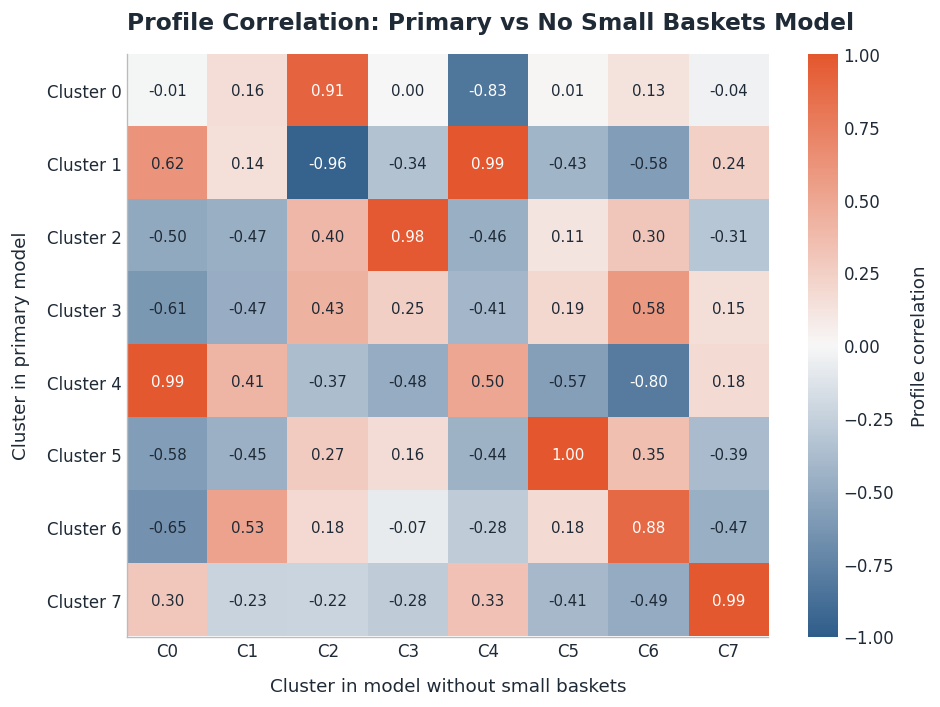

In [48]:
profile_correlations = pd.DataFrame(
    index=profile_difference.index,
    columns=profile_difference_without_small.index,
    dtype=float
)

for original_cluster in profile_difference.index:
    for filtered_cluster in profile_difference_without_small.index:

        profile_correlations.loc[
            original_cluster,
            filtered_cluster
        ] = profile_difference.loc[
            original_cluster
        ].corr(
            profile_difference_without_small.loc[
                filtered_cluster
            ]
        )

fig, ax = plt.subplots(figsize=(8, 6))
im = annotated_heatmap(ax, profile_correlations, cmap_diverging, vmin=-1, vmax=1, fmt="{:.2f}", fontsize=9)

ax.set_xticks(range(profile_correlations.shape[1]))
ax.set_xticklabels([f"C{c}" for c in profile_correlations.columns])
ax.set_yticks(range(profile_correlations.shape[0]))
ax.set_yticklabels([cluster_label(c) for c in profile_correlations.index])
ax.set_xlabel("Cluster in model without small baskets")
ax.set_ylabel("Cluster in primary model")
ax.set_title("Profile Correlation: Primary vs No Small Baskets Model", fontsize=14)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Profile correlation")
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

In [49]:
best_profile_matches = pd.DataFrame({
    "Closest Filtered Cluster": profile_correlations.idxmax(axis=1),
    "Profile Correlation": profile_correlations.max(axis=1),
})
display(best_profile_matches.round(2))

,Closest Filtered Cluster,Profile Correlation
Cluster,,
0,2,0.91
1,4,0.99
2,3,0.98
3,6,0.58
4,0,0.99
5,5,1.00
6,6,0.88
7,7,0.99


,Orders,Small_Basket_Share
Cluster,,
0,15140,34.51
1,24560,29.25
2,32365,8.34
3,10609,46.96
4,42486,6.42
5,22282,20.22
6,14497,42.74
7,38061,1.94


Overall small-basket share: 17.13%


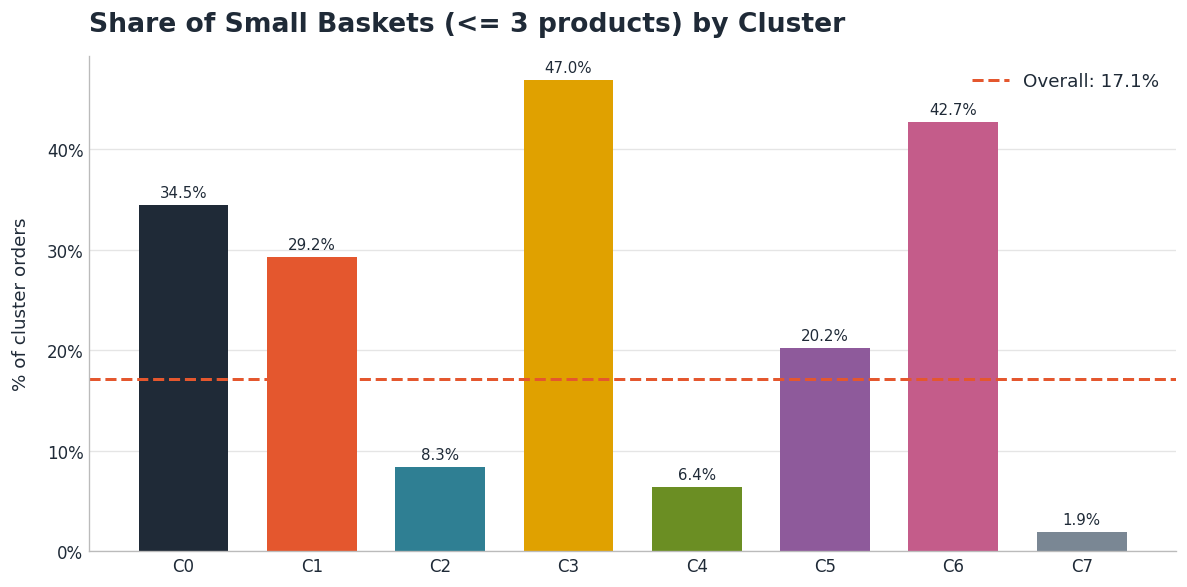

In [50]:
small_basket_flag = order_totals <= small_basket_max
overall_small_share = small_basket_flag.mean() * 100

small_basket_by_cluster = (
    pd.DataFrame({"Cluster": primary_labels, "Small Basket": small_basket_flag})
    .groupby("Cluster")["Small Basket"]
    .agg(Orders="size", Small_Basket_Share="mean")
)
small_basket_by_cluster["Small_Basket_Share"] *= 100
display(small_basket_by_cluster.round(2))
print(f"Overall small-basket share: {overall_small_share:.2f}%")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar([cluster_label(c, short=True) for c in small_basket_by_cluster.index],
              small_basket_by_cluster["Small_Basket_Share"],
              color=[cluster_color(c) for c in small_basket_by_cluster.index], width=0.7)
ax.bar_label(bars, fmt="{:.1f}%", padding=3, fontsize=9, color=dark)
ax.axhline(overall_small_share, color=accent, linestyle="--", linewidth=1.8,
           label=f"Overall: {overall_small_share:.1f}%")
ax.legend(loc="upper right")
style_axes(ax, f"Share of Small Baskets (<= {small_basket_max} products) by Cluster", "", "% of cluster orders")
percent_axis(ax, "y")

plt.tight_layout()
plt.show()

#### Small Basket Concentration by Cluster

Small baskets are not distributed uniformly across the segmentation.

Their concentration differs substantially between clusters, suggesting that small orders may influence some shopping profiles more strongly than others.

This distribution is considered together with the filtered model comparison when evaluating cluster stability.

#### **Finding**

Removing orders containing three products or fewer retains **82.87%** of the dataset.

The filtered solution reaches a silhouette score of approximately **0.125**, compared with **0.171** in the primary model, while cluster assignments show moderate agreement with the original segmentation with an ARI of **0.529**.

Most cluster profiles remain highly similar after removing small baskets. Six of the eight primary profiles have a corresponding filtered profile with correlation above **0.90**, while another reaches **0.88**.

Cluster 3 is the main exception, with a profile correlation of approximately **0.58**.

Small baskets are also unevenly distributed across clusters. Cluster 3 contains the highest small basket share at approximately **47%**, although other clusters with many small baskets remain considerably more stable.

The main shopping patterns therefore persist after removing small orders, but one part of the segmentation is more sensitive to basket size and should be interpreted with additional caution.

### 7.3 Random Seed Stability

K Means depends on the initialization of its centroids.

The selected model is therefore fitted using several random seeds and each resulting partition is compared with the primary solution using the Adjusted Rand Index.

Higher values indicate greater agreement with the primary partition.

,ARI vs primary model
1,0.952
2,0.944
3,0.981
4,0.977
5,0.977


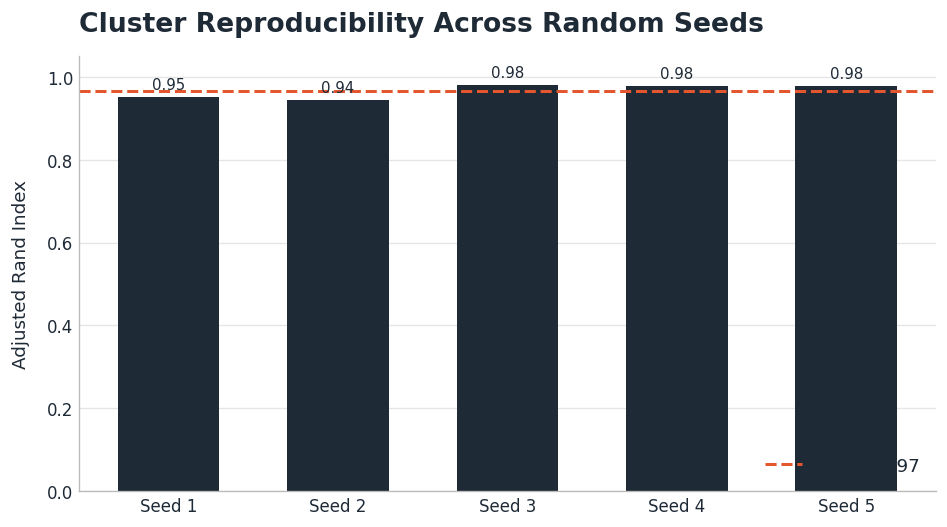

In [51]:
seed_stability = pd.Series({
    seed: adjusted_rand_score(
        primary_labels,
        KMeans(
            n_clusters=final_k,
            random_state=seed,
            n_init=final_n_init
        ).fit_predict(primary_scores)
    )
    for seed in seed_values
}, name="ARI vs primary model")

display(
    seed_stability
    .round(3)
    .to_frame()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([f"Seed {s}" for s in seed_stability.index], seed_stability.values, color=dark, width=0.6)
ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=9, color=dark)
ax.axhline(seed_stability.mean(), color=accent, linestyle="--", linewidth=1.8,
           label=f"Mean: {seed_stability.mean():.2f}")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
style_axes(ax, "Cluster Reproducibility Across Random Seeds", "", "Adjusted Rand Index")

plt.tight_layout()
plt.show()

#### **Finding**

The final K Means configuration is highly consistent across the tested random seeds.

Adjusted Rand Index values range from approximately **0.944 to 0.981**, with an average agreement of approximately **0.966** relative to the primary solution.

This indicates that using multiple centroid initializations produces a highly reproducible partition and that the selected solution is not strongly dependent on one favorable random initialization.

### 7.4 Shopping Mission Labels

After evaluating cluster composition and robustness, each cluster is assigned a descriptive label.

The labels summarize the most distinctive basket characteristics observed in each group. They are intended as concise descriptions of basket structure rather than direct statements about customer intent.

The final shopping mission labels are:

| Cluster | Shopping Mission |
| --- | --- |
| 0 | Dairy Core |
| 1 | Produce Core |
| 2 | Frozen Variety |
| 3 | Household Pantry |
| 4 | Fresh Essentials |
| 5 | Snack Basket |
| 6 | Beverage Basket |
| 7 | Pantry Staples |

`Dairy Core` and `Produce Core` represent baskets where one department clearly forms the center of the purchase.

`Frozen Variety` contains a strong frozen component while maintaining relatively large and diverse baskets.

`Household Pantry` combines household and pantry products and is interpreted more cautiously because it showed the lowest stability in the small basket sensitivity analysis.

`Fresh Essentials` combines elevated produce and dairy participation without being dominated by only one department.

`Snack Basket` and `Beverage Basket` represent more specialized patterns with strong concentration in their corresponding departments.

`Pantry Staples` contains larger and more diverse baskets with elevated pantry, canned goods, dry goods, and produce participation.

In [52]:
cluster_names = {
    0: "Dairy Core",
    1: "Produce Core",
    2: "Frozen Variety",
    3: "Household Pantry",
    4: "Fresh Essentials",
    5: "Snack Basket",
    6: "Beverage Basket",
    7: "Pantry Staples"
}

## 8. Behavioral Profiling of Shopping Missions

The clustering model uses only department composition.

Contextual variables that were not included in the clustering process can therefore be used to examine whether the resulting missions also differ in shopping trip characteristics.

The analysis compares basket size, department diversity, item reorder behavior, order timing, and the interval since the previous observed order.

In [53]:
order_context = (
    df.groupby("order_id")
      .agg(user_id=("user_id", "first"),
           order_number=("order_number", "first"),
           order_dow=("order_dow", "first"),
           order_hour=("order_hour_of_day", "first"),
           days_since_prior=("days_since_prior_order", "first"),
           reorder_rate=("reordered", "mean"))
      .reindex(primary_labels.index)
)
order_context["basket_size"] = order_totals
order_context["n_departments"] = departments_per_order
order_context["Cluster"] = primary_labels

by_cluster = order_context.groupby("Cluster")

context_summary = pd.DataFrame({
    "Orders": by_cluster.size(),
    "Median Basket Size": by_cluster["basket_size"].median(),
    "Avg Departments": by_cluster["n_departments"].mean(),
    "Mean Item Reorder Rate (%)": by_cluster["reorder_rate"].mean() * 100,
    "Avg Hour of Day": by_cluster["order_hour"].mean(),
    "Avg Days Since Prior": by_cluster["days_since_prior"].mean(),
    "First Orders (%)": by_cluster["order_number"].apply(lambda s: (s == 1).mean() * 100),
})
display(context_summary.round(2))

,Orders,Median Basket Size,Avg Departments,Mean Item Reorder Rate (%),Avg Hour of Day,Avg Days Since Prior,First Orders (%)
Cluster,,,,,,,
0,15140,5.0,3.47,63.59,13.28,10.65,5.85
1,24560,6.0,2.91,62.72,13.42,10.35,6.07
2,32365,11.0,6.25,57.78,13.73,11.82,6.69
3,10609,4.0,3.17,46.24,13.52,11.74,7.24
4,42486,9.0,4.63,65.93,13.47,10.59,5.62
5,22282,7.0,4.46,60.26,13.28,10.82,5.84
6,14497,4.0,2.83,62.63,13.28,11.15,6.31
7,38061,13.0,6.58,54.17,13.46,11.18,6.15


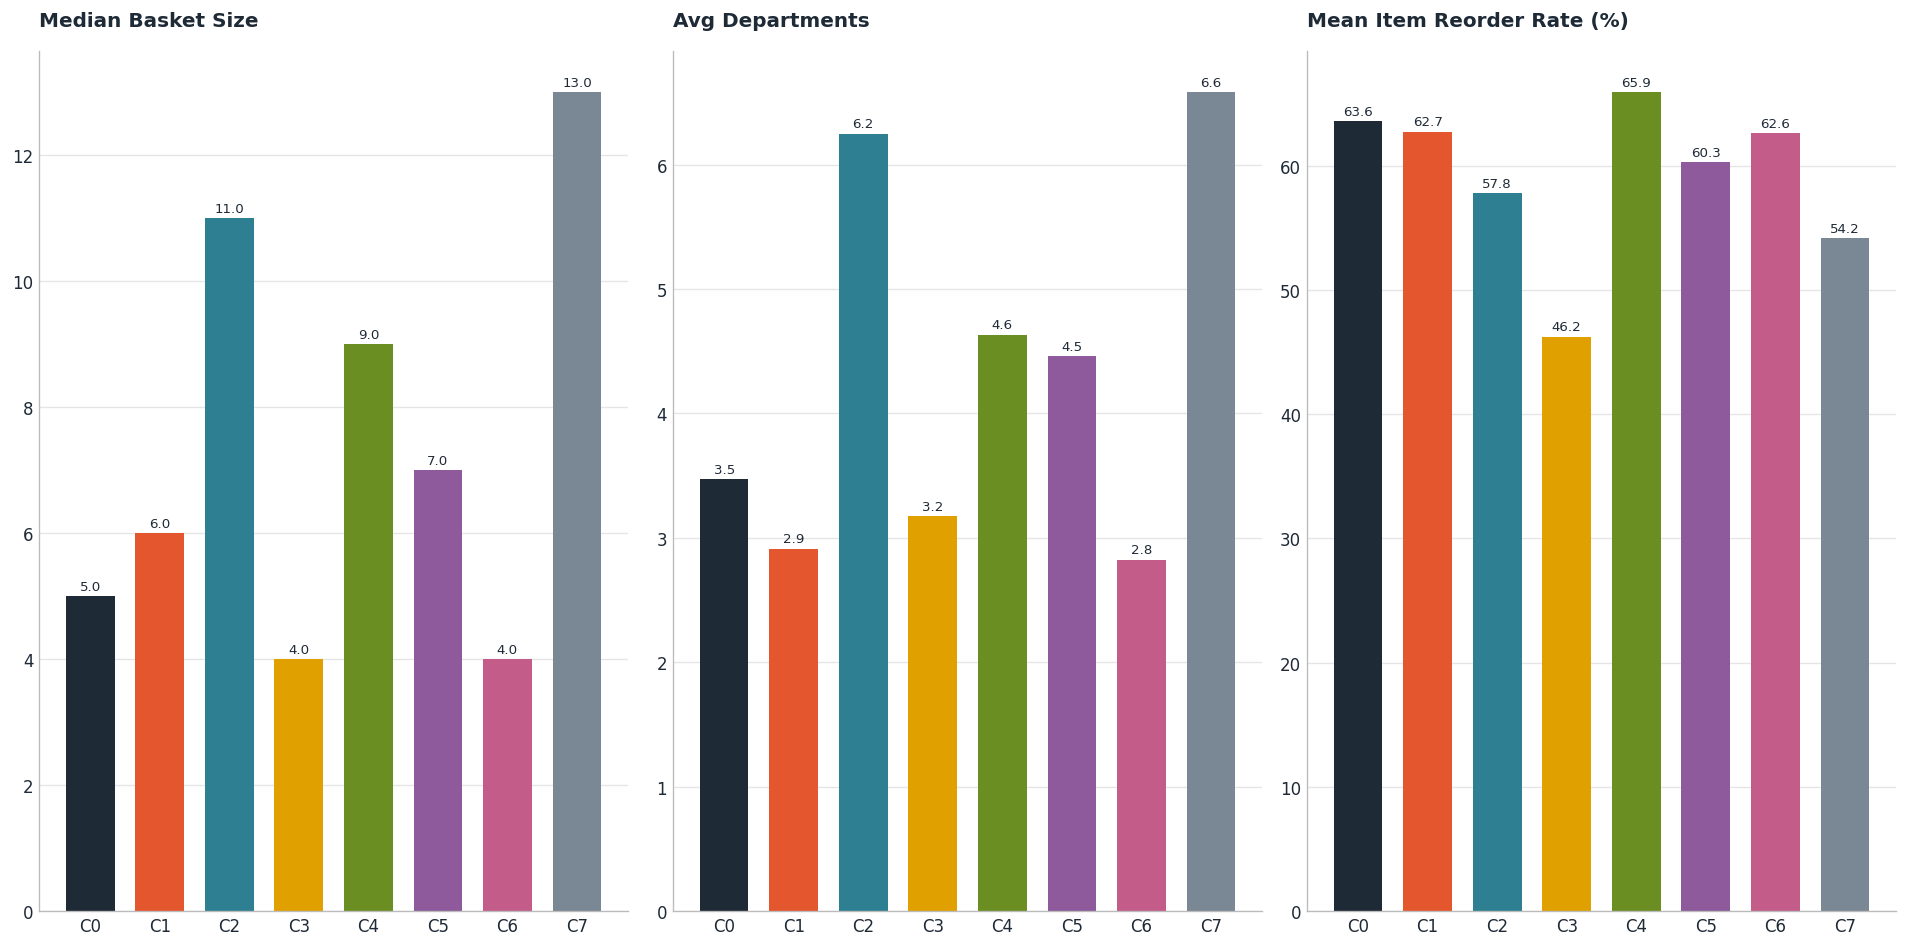

In [54]:
metrics = [
    "Median Basket Size",
    "Avg Departments",
    "Mean Item Reorder Rate (%)"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 8))

for ax, metric in zip(axes.ravel(), metrics):
    values = context_summary[metric]
    bars = ax.bar([cluster_label(c, short=True) for c in values.index], values.values,
                  color=[cluster_color(c) for c in values.index], width=0.7)
    ax.bar_label(bars, fmt="{:.1f}", padding=2, fontsize=8, color=dark)
    style_axes(ax, metric, "", "", title_size=12)

plt.tight_layout()
plt.show()

#### **Finding**

The contextual variables provide additional behavioral support for the composition based clusters.

Basket size and department diversity vary substantially across missions. Some clusters represent smaller and more focused purchases, while others contain larger baskets spanning a broader range of departments.

Mean item reorder rates also differ between missions, ranging from approximately **46% to 66%**.

In contrast, average order hour, time since the previous observed order, and the proportion of first orders remain relatively similar across clusters.

The shopping missions therefore differ mainly in basket composition and shopping trip scope rather than in strong temporal purchasing patterns.

## 9. Mission Persistence: Do Customers Repeat the Same Mission?

Customer histories in this dataset are incomplete.

For this reason, the longitudinal analysis is restricted to users for whom two consecutively numbered orders are both observed.

A high repeat rate alone does not necessarily indicate persistence because larger missions have a higher probability of being observed again by chance.

The repeat rate for each mission is therefore compared with its overall frequency among destination orders.

In [55]:
sequence = (
    order_context[["user_id", "order_number", "Cluster"]]
    .sort_values(["user_id", "order_number"])
)
by_user = sequence.groupby("user_id")
sequence["next_cluster"] = by_user["Cluster"].shift(-1)
sequence["next_order_number"] = by_user["order_number"].shift(-1)

transitions = sequence.dropna(subset=["next_cluster"]).copy()
if consecutive_only:
    transitions = transitions[transitions["next_order_number"] == transitions["order_number"] + 1]
transitions["next_cluster"] = transitions["next_cluster"].astype(int)

print(f"Users with at least one transition: {transitions['user_id'].nunique():,}")
print(f"Order-to-order transitions:         {len(transitions):,}")

transition_counts = pd.crosstab(transitions["Cluster"], transitions["next_cluster"]).reindex(
    index=cluster_ids, columns=cluster_ids, fill_value=0)
transition_probs = transition_counts.div(transition_counts.sum(axis=1), axis=0) * 100

baseline = transition_counts.sum(axis=0) / transition_counts.values.sum() * 100
repeat_rate = pd.Series(np.diag(transition_probs.values), index=cluster_ids)

persistence = pd.DataFrame({
    "Transitions From Mission": transition_counts.sum(axis=1),
    "Repeat Rate (%)": repeat_rate,
    "Chance Baseline (%)": baseline,
    "Lift": repeat_rate / baseline,
})
display(persistence.round(2))

overall_repeat = np.trace(transition_counts.values) / transition_counts.values.sum() * 100
print(f"Overall repeat rate: {overall_repeat:.1f}%")

Users with at least one transition: 10,236
Order-to-order transitions:         11,318


,Transitions From Mission,Repeat Rate (%),Chance Baseline (%),Lift
0,865,27.98,7.56,3.70
1,1334,35.16,12.47,2.82
2,1909,38.08,15.90,2.39
3,586,27.99,5.55,5.04
4,2354,38.15,20.55,1.86
5,1266,36.02,10.79,3.34
6,833,34.57,7.43,4.65
7,2171,34.13,19.75,1.73


Overall repeat rate: 35.2%


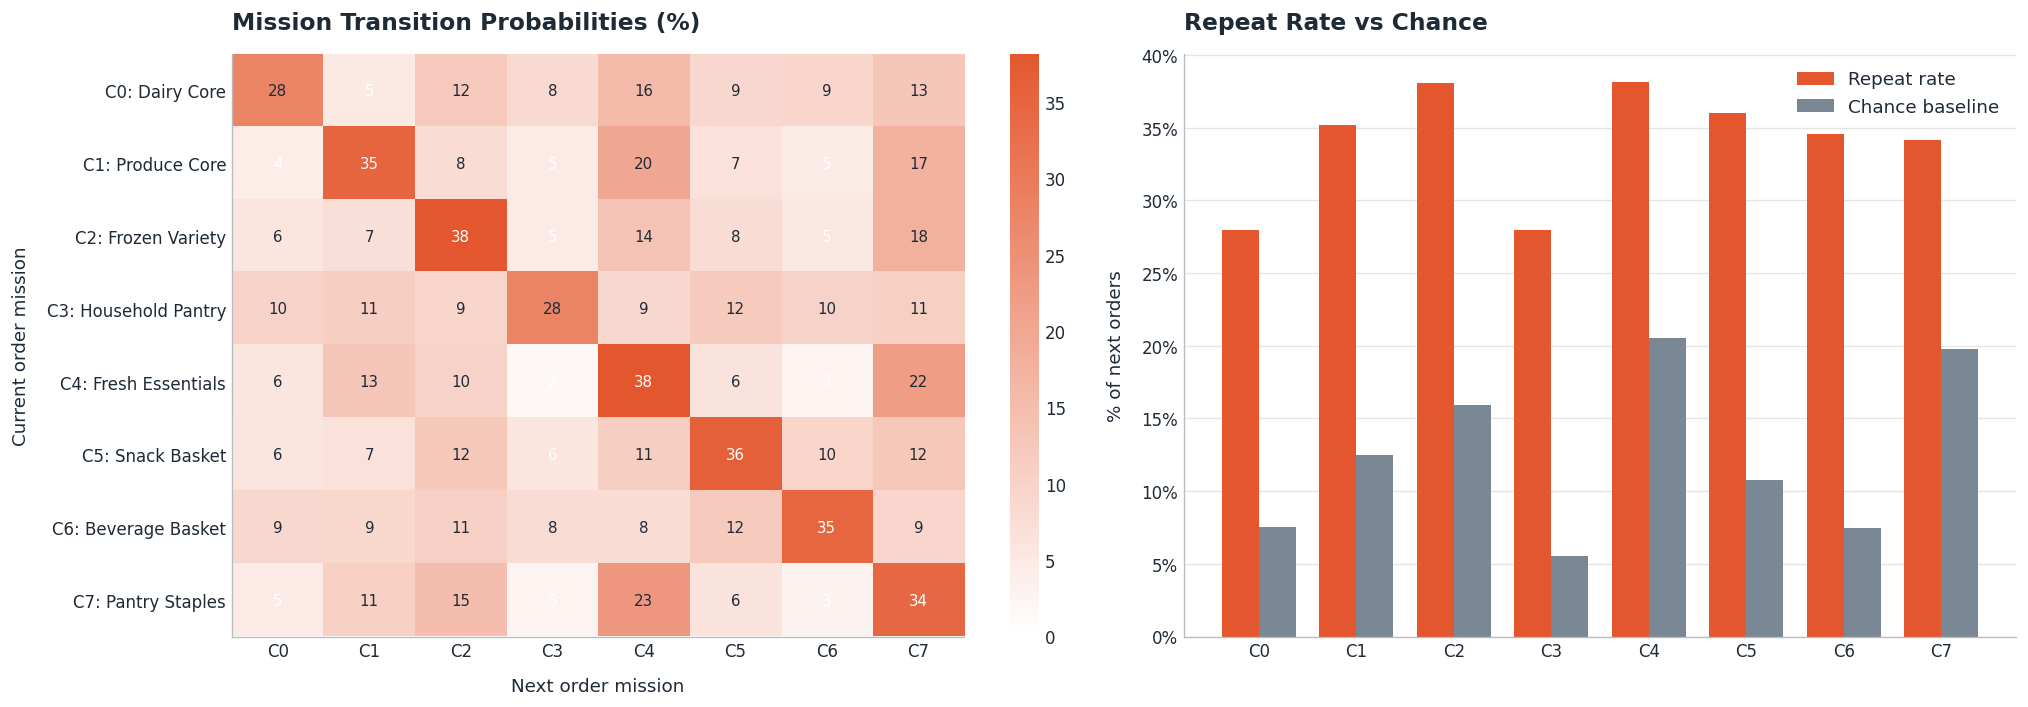

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.1, 1]})

im = annotated_heatmap(axes[0], transition_probs, cmap_sequential,
                       vmin=0, vmax=transition_probs.values.max(), fmt="{:.0f}", fontsize=9)
axes[0].set_xticks(range(len(cluster_ids)))
axes[0].set_xticklabels([f"C{c}" for c in cluster_ids])
axes[0].set_yticks(range(len(cluster_ids)))
axes[0].set_yticklabels([cluster_label(c) for c in cluster_ids])
axes[0].set_xlabel("Next order mission")
axes[0].set_ylabel("Current order mission")
axes[0].set_title("Mission Transition Probabilities (%)", fontsize=14)
cbar = plt.colorbar(im, ax=axes[0])
cbar.outline.set_visible(False)

positions = np.arange(len(cluster_ids))
width = 0.38
axes[1].bar(positions - width / 2, repeat_rate.values, width, color=accent, label="Repeat rate")
axes[1].bar(positions + width / 2, baseline.values, width, color=grey, label="Chance baseline")
axes[1].set_xticks(positions)
axes[1].set_xticklabels([f"C{c}" for c in cluster_ids])
style_axes(axes[1], "Repeat Rate vs Chance", "", "% of next orders", title_size=14)
percent_axis(axes[1], "y")
axes[1].legend()

plt.tight_layout()
plt.show()

### **Finding**

Among users with consecutively observed orders, the same shopping mission is repeated in approximately **35.2%** of order to order transitions.

For every mission, the observed repeat rate is higher than the corresponding chance baseline.

Repeat rate lift ranges from approximately **1.73 to 5.04**, indicating meaningful persistence in the type of shopping event performed by the same customer.

At the same time, most observed transitions move to a different mission.

This supports the idea that a customer should not necessarily be represented by one fixed shopping segment.

Because complete customer histories are not available, these results describe only the subset of consecutive orders that can be observed directly in the dataset.

## 10. Conclusions

The most important result of this project was not simply the identification of eight clusters, but the change in what the data were able to support.

The original goal was to segment customers according to purchasing behavior. However, deeper exploration showed that the available customer histories were highly incomplete. This made it difficult to interpret customer level department proportions as stable long term preferences.

The analysis was therefore reframed around individual orders.

Using department composition, the final model identified eight recurring shopping patterns with distinct basket structures. These patterns differ not only in their dominant departments, but also in the combinations of departments that appear together.

The dominant department baseline showed that several missions can share the same most common department while maintaining different overall basket profiles. This indicates that the clustering captures more information than a simple assignment based on the largest department share.

Behavioral profiling also showed meaningful differences in basket size, department diversity, and mean item reorder rate. In contrast, order hour and time since the previous observed purchase showed relatively little variation between missions.

The longitudinal analysis provided an additional insight. The same mission was repeated in approximately 35.2 percent of consecutive observed transitions, and every mission showed a repeat rate above its corresponding chance baseline.

However, most transitions moved to a different mission.

This suggests that shopping missions are better interpreted as recurring types of shopping events rather than permanent customer segments. The same customer can perform different types of purchases at different points in time.

Overall, the project shows that order composition contains meaningful and recurring structure, while also demonstrating the importance of allowing the data to redefine the original analytical question.

## 11. Limitations

The identified shopping missions should be interpreted as descriptive patterns rather than direct observations of customer intent.

The clustering solution has a relatively modest silhouette score of approximately 0.17, indicating that the missions overlap rather than forming completely separated groups. This is consistent with grocery purchasing behavior, where baskets can combine characteristics from several patterns.

Most cluster profiles remained stable during the sensitivity analysis, but the Household Pantry mission showed substantially lower stability after removing very small baskets. This mission should therefore be interpreted more cautiously than the others.

Customer histories are incomplete for most users in the dataset. For this reason, the longitudinal analysis is limited to the subset of consecutively observed orders and cannot represent complete customer behavior over time.

The analysis is also performed at the department level. Product level differences within the same department are therefore not represented in the clustering.

Price, total spending, promotions, and other economic information are not available, which limits the ability to distinguish shopping missions based on purchase value or sensitivity to price.

Finally, K Means assigns every order to exactly one cluster even when some baskets may lie between multiple shopping patterns. The resulting missions should therefore be understood as useful summaries of recurring basket structures rather than perfectly separated categories.